## Markov Modulated Shifted Wishart Process

To run the Monte Carlo Simulation you need to run the following cells

0- import the module 

1- first cell in "Estimated PArameters" (only for S&P and Apple)

2- for computing the price by formula run all cells in # Characteristic function for Shifted Wishart Process and option pricing by formula

3- 5 (all) cells in the part "Monte Carlo Simulation for generating three matrix processes"

4- first three cells in "Monte Carlo Simulation for Option Pricing and c.f."

In [2]:
import pandas as pd
import numpy as np
import scipy
import scipy.stats as ss
import matplotlib.pyplot as plt
#from mpl_toolkits.mplot3d import Axes3D
from datetime import datetime, date
import datetime
import yfinance as yf
from hmmlearn import hmm
#from random import seed
#from random import random
from arch import arch_model
from scipy.linalg import expm

Getting Data

In [2]:
data_0= pd.read_csv("data/data.csv")
data_0= np.log(data_0[["S&P 500 in USD", "AAPL"]]/data_0[["S&P 500 in USD", "AAPL"]].shift(1))
data_0_cov= 252 * data_0.cov() 
data_0_cov

,S&P 500 in USD,AAPL
S&P 500 in USD,0.036172,0.038994
AAPL,0.038994,0.108463


In [1]:
# Getting the VIX data

# If needed: pip install yfinance
# python -m pip install yfinance --upgrade

import yfinance as yf
import pandas as pd

# Yahoo Finance ticker for VIX index
ticker = "^VIX"

# Download full daily history
df = yf.download(ticker, period="max", interval="1d", auto_adjust=False)

# Ensure a clean datetime index
df.index.name = "Date"

# Save to CSV (change the path as you like)
output_path = "data/vix_daily.csv"
df.to_csv(output_path)

print(f"Saved {len(df):,} rows to {output_path}")
print(df.tail())

Failed to get ticker '^VIX' reason: Failed to perform, curl: (28) Operation timed out after 10003 milliseconds with 0 bytes received. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.
[*********************100%***********************]  1 of 1 completed


Saved 9,004 rows to data/vix_daily.csv
Price       Adj Close      Close       High    Low       Open Volume
Ticker           ^VIX       ^VIX       ^VIX   ^VIX       ^VIX   ^VIX
Date                                                                
2025-09-25  16.740000  16.740000  17.740000  16.32  16.549999      0
2025-09-26  15.290000  15.290000  17.049999  15.29  16.889999      0
2025-09-29  16.120001  16.120001  16.290001  15.74  15.840000      0
2025-09-30  16.280001  16.280001  16.700001  16.02  16.490000      0
2025-10-01  16.770000  16.770000  17.280001  16.74  17.280001      0


In [2]:
#tickers= ["^GSPC", "^GDAXI", "EURUSD=X", "RY", "BMO", "^VIX", "^COR3M", "^RUA", "NVDA", "INTC", "TSLA", "GOOG", "AAPL", "^TYX"]
start="2000-01-01",
end="2025-12-31",
#tickers= ["^TYX"]
tickers= ["^FVX"]
t= "^FVX"
df = yf.download(
                    t, start=start, end=end, progress=False
                )
df.to_csv("data/"+t+".csv", sep=",", encoding= "utf-8")
for tic in tickers:
    ticker= yf.Ticker(tic)
    #history = ticker.history(period="max")
    history = ticker.history( start=start, end=end)
    history.to_csv("data/"+tic+".csv", sep=",", encoding= "utf-8")

/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_52965/645300134.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(

1 Failed download:
['^FVX']: ValueError("Unable to parse input dt ('2000-01-01',) of type <class 'tuple'>")


ValueError: Unable to parse input dt ('2000-01-01',) of type <class 'tuple'>

In [3]:
import yfinance as yf
tickers = ["AGG","BND","LQD","HYG","TLT","IEF","SHY","TIP","SGOV","MUB","VTEB","TFI","EMB","IGOV","BWX","BNDX"]
df = yf.download(" ".join(tickers), start="2000-01-01", end="2025-12-31", auto_adjust=True)["Close"]
print(df.tail())
df.to_csv("data/"+"bonds"+".csv", sep=",", encoding= "utf-8")


[*********************100%***********************]  16 of 16 completed


Ticker             AGG        BND       BNDX        BWX        EMB        HYG  \
Date                                                                            
2025-09-24  100.139999  74.290001  49.380001  22.930000  95.500000  81.150002   
2025-09-25  100.000000  74.209999  49.349998  22.790001  95.260002  80.919998   
2025-09-26  100.070000  74.209999  49.389999  22.850000  95.230003  81.080002   
2025-09-29  100.260002  74.400002  49.450001  22.969999  95.389999  81.220001   
2025-09-30  100.359901  74.449402  49.459999  22.990000  95.345001  81.195000   

Ticker            IEF       IGOV         LQD         MUB        SGOV  \
Date                                                                   
2025-09-24  96.480003  42.419998  111.260002  106.349998  100.650002   
2025-09-25  96.269997  42.150002  111.059998  106.250000  100.660004   
2025-09-26  96.220001  42.340000  111.209999  106.260002  100.690002   
2025-09-29  96.500000  42.560001  111.580002  106.419998  100.699997   


In [4]:
# pip install yfinance pandas
import os
import time
import math
from typing import List, Iterable, Dict
import pandas as pd
import yfinance as yf

TICKERS = ["AGG","BND","LQD","HYG","TLT","IEF","SHY","TIP",
           "SGOV","MUB","VTEB","TFI","EMB","IGOV","BWX","BNDX"]

START = "2000-01-01"
END   = "2025-12-31"
OUT_DIR = "data_bonds"

# ------------ helpers ------------
def chunked(seq: List[str], n: int) -> Iterable[List[str]]:
    for i in range(0, len(seq), n):
        yield seq[i:i+n]

def safe_download_batch(tickers: List[str],
                        start: str,
                        end: str,
                        auto_adjust: bool = True,
                        threads: bool = False,
                        max_retries: int = 5,
                        initial_sleep: float = 2.0) -> pd.DataFrame:
    """
    Download a batch with retry/backoff to handle YF rate limiting.
    Returns a (possibly partial) dataframe; empty if all failed.
    """
    sleep = initial_sleep
    for attempt in range(1, max_retries + 1):
        try:
            df = yf.download(
                tickers=" ".join(tickers),
                start=start,
                end=end,
                auto_adjust=auto_adjust,
                progress=False,
                threads=threads,
            )
            # When multiple tickers are passed, yfinance returns a column MultiIndex.
            if isinstance(df.columns, pd.MultiIndex):
                close = df["Close"] if auto_adjust else (df["Adj Close"] if "Adj Close" in df.columns.levels[0] else df["Close"])
            else:
                # Single ticker case
                close = df[[ "Close" if auto_adjust else ("Adj Close" if "Adj Close" in df.columns else "Close") ]]
                close.columns = [tickers[0]]
            return close
        except Exception as e:
            # Specifically back off on rate limit; also covers transient network hiccups
            if "Rate limited" in str(e) or "Too Many Requests" in str(e) or "YFRateLimitError" in str(e):
                time.sleep(sleep)
                sleep = min(sleep * 2, 60)  # cap backoff
            else:
                # Non-rate-limit errors: short pause then retry
                time.sleep(2)
    # If we get here, batch failed after retries
    return pd.DataFrame()

def download_bonds_resilient(tickers: List[str],
                             start: str,
                             end: str,
                             out_dir: str = OUT_DIR,
                             batch_size: int = 4,
                             pause_between_batches: float = 3.0) -> pd.DataFrame:
    os.makedirs(out_dir, exist_ok=True)
    combined = pd.DataFrame()

    # 1) Try in small batches (no threading)
    for batch in chunked(tickers, batch_size):
        close = safe_download_batch(batch, start, end, auto_adjust=True, threads=False)
        if close.empty:
            # 2) Fall back to downloading one-by-one for this batch
            parts = []
            for t in batch:
                single = safe_download_batch([t], start, end, auto_adjust=True, threads=False)
                if not single.empty:
                    parts.append(single)
                    # Save per-ticker full OHLCV too
                    full = yf.download(t, start=start, end=end, auto_adjust=True, progress=False, threads=False)
                    if not full.empty:
                        full.index.name = "Date"
                        full.to_csv(os.path.join(out_dir, f"{t}.csv"))
                # brief pause to be gentle
                time.sleep(1.5)
            if parts:
                close = pd.concat(parts, axis=1)
            else:
                close = pd.DataFrame()

        # Append to combined
        if not close.empty:
            # Save per-ticker if not already saved
            for t in close.columns:
                # If not saved above, save now
                path = os.path.join(out_dir, f"{t}.csv")
                if not os.path.exists(path):
                    full = yf.download(t, start=start, end=end, auto_adjust=True, progress=False, threads=False)
                    if not full.empty:
                        full.index.name = "Date"
                        full.to_csv(path)
            combined = close if combined.empty else combined.join(close, how="outer")

        time.sleep(pause_between_batches)

    if combined.empty:
        raise RuntimeError("All downloads failed due to rate limiting. Try increasing pauses or running later.")

    combined.index.name = "Date"
    combined = combined.sort_index()
    combined.to_csv(os.path.join(out_dir, "bond_prices_combined.csv"))
    print(f"Saved combined close series to {os.path.join(out_dir, 'bond_prices_combined.csv')}")
    return combined

if __name__ == "__main__":
    df = download_bonds_resilient(TICKERS, START, END, OUT_DIR, batch_size=4, pause_between_batches=3.0)
    print(df.tail())


Saved combined close series to data_bonds/bond_prices_combined.csv
Ticker             AGG        BND        HYG         LQD        IEF  \
Date                                                                  
2025-09-24  100.139999  74.290001  81.150002  111.260002  96.480003   
2025-09-25  100.000000  74.209999  80.919998  111.059998  96.269997   
2025-09-26  100.070000  74.209999  81.080002  111.209999  96.220001   
2025-09-29  100.260002  74.400002  81.220001  111.580002  96.500000   
2025-09-30  100.379997  74.466400  81.184998  111.684998  96.635002   

Ticker            SHY         TIP        TLT         MUB        SGOV  \
Date                                                                   
2025-09-24  82.910004  111.269997  88.980003  106.349998  100.650002   
2025-09-25  82.839996  111.089996  88.980003  106.250000  100.660004   
2025-09-26  82.889999  111.110001  88.900002  106.260002  100.690002   
2025-09-29  82.919998  111.250000  89.629997  106.419998  100.699997   
202

In [7]:
df.to_csv("data/bond_data.csv")

In [2]:
import os, time, random
from typing import List, Dict
import pandas as pd
import yfinance as yf
import requests
from urllib3.util.retry import Retry
from requests.adapters import HTTPAdapter

TICKERS = ["AGG","BND","LQD","HYG","TLT","IEF","SHY","TIP",
           "SGOV","MUB","VTEB","TFI","EMB","IGOV","BWX","BNDX"]

START = "2000-01-01"
END   = "2025-12-31"
OUT_DIR = "data_bonds"

# ---------- HTTP session with retries ----------
def make_retrying_session(total=8, backoff_factor=0.8) -> requests.Session:
    # Retry on 429 (rate limit) and common 5xx errors
    retry = Retry(
        total=total,
        read=total,
        connect=total,
        backoff_factor=backoff_factor,  # exponential backoff
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(["GET", "POST"]),
        raise_on_status=False,
    )
    sess = requests.Session()
    adapter = HTTPAdapter(max_retries=retry, pool_connections=5, pool_maxsize=5)
    sess.mount("http://", adapter)
    sess.mount("https://", adapter)
    # A user-agent helps with some CDNs
    sess.headers.update({"User-Agent": "Mozilla/5.0 (compatible; yfinance-retry/1.0)"})
    return sess

# ---------- download one ticker with backoff ----------
def download_one(ticker: str,
                 start: str,
                 end: str,
                 session: requests.Session,
                 auto_adjust: bool = True,
                 timeout: int = 30,
                 max_attempts: int = 8) -> pd.DataFrame:
    sleep = 2.0
    for attempt in range(1, max_attempts + 1):
        try:
            df = yf.download(
                ticker,
                start=start,
                end=end,
                auto_adjust=auto_adjust,
                progress=False,
                threads=False,        # avoid parallel calls
                timeout=timeout,      # yfinance supports this param
                session=session       # reuse our retrying Session
            )
            if df is not None and not df.empty:
                return df
            # Empty but no exception — likely throttled or blocked. Back off and retry.
            time.sleep(sleep + random.uniform(0, 0.75))
            sleep = min(sleep * 1.75, 60)
        except Exception as e:
            msg = str(e)
            # Back off more if explicitly rate-limited
            if any(s in msg for s in ["429", "Too Many Requests", "Rate", "limit", "YFRateLimitError"]):
                time.sleep(sleep + random.uniform(0, 0.75))
                sleep = min(sleep * 1.75, 60)
            else:
                # Transient or other network errors
                time.sleep(2.0 + random.uniform(0, 0.75))
    return pd.DataFrame()

def download_bonds_careful(
    tickers: List[str],
    start: str,
    end: str,
    out_dir: str = OUT_DIR,
    pause_between: float = 4.0
) -> Dict[str, str]:
    os.makedirs(out_dir, exist_ok=True)
    session = make_retrying_session()
    results = {}
    closes = []

    for t in tickers:
        print(f"Fetching {t} ...")
        df = download_one(t, start, end, session=session, auto_adjust=True, timeout=45)
        if not df.empty:
            # Save full OHLCV
            df.index.name = "Date"
            df.to_csv(os.path.join(out_dir, f"{t}.csv"))
            # Keep Close (auto-adjusted) for combined file
            close = df[["Close"]].rename(columns={"Close": t})
            closes.append(close)
            results[t] = "ok"
            print(f"  -> OK ({len(df):,} rows)")
        else:
            results[t] = "failed"
            print(f"  -> FAILED (empty after retries)")
        # Be gentle with the server
        time.sleep(pause_between + random.uniform(0.0, 1.0))

    if closes:
        combined = pd.concat(closes, axis=1).sort_index()
        combined.index.name = "Date"
        combined.to_csv(os.path.join(out_dir, "bond_prices_combined.csv"))
        print(f"\nSaved combined Close series to {os.path.join(out_dir, 'bond_prices_combined.csv')}")
    else:
        print("\nNo data could be saved. Likely a hard block or network issue.")

    return results

if __name__ == "__main__":
    summary = download_bonds_careful(TICKERS, START, END, OUT_DIR, pause_between=6.0)
    print("\nSummary:", summary)


Fetching AGG ...
  -> FAILED (empty after retries)
Fetching BND ...
  -> FAILED (empty after retries)
Fetching LQD ...
  -> FAILED (empty after retries)
Fetching HYG ...
  -> FAILED (empty after retries)
Fetching TLT ...
  -> FAILED (empty after retries)
Fetching IEF ...
  -> FAILED (empty after retries)
Fetching SHY ...
  -> FAILED (empty after retries)
Fetching TIP ...
  -> FAILED (empty after retries)
Fetching SGOV ...
  -> FAILED (empty after retries)
Fetching MUB ...
  -> FAILED (empty after retries)
Fetching VTEB ...
  -> FAILED (empty after retries)
Fetching TFI ...
  -> FAILED (empty after retries)
Fetching EMB ...
  -> FAILED (empty after retries)
Fetching IGOV ...
  -> FAILED (empty after retries)
Fetching BWX ...
  -> FAILED (empty after retries)
Fetching BNDX ...
  -> FAILED (empty after retries)

No data could be saved. Likely a hard block or network issue.

Summary: {'AGG': 'failed', 'BND': 'failed', 'LQD': 'failed', 'HYG': 'failed', 'TLT': 'failed', 'IEF': 'failed', 'SHY

Data Preprocessing

In [32]:
#Reading data from csv file
#data= pd.read_csv("data/data.csv")
data= pd.read_csv("data/data_2014.csv")

In [12]:
def date_format(data):
    Date_= []
    Date= pd.to_datetime(data["Date"])
    for d in Date:
        Date_.append(d.date().strftime('%Y-%m-%d'))
    data["Date"]= Date_
    return data
EuroUSD= pd.read_csv("data/EURUSD=X.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "Close_EuroUSD"})
SP= pd.read_csv("data/^GSPC.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "Close_SP"})
DAX= pd.read_csv("data/^GDAXI.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "Close_DAX"})
RBC= pd.read_csv("data/RY.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "Close_RBC"})
BMO= pd.read_csv("data/BMO.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "Close_BMO"})
RUA= pd.read_csv("data/^RUA.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "RUA"})
AAPL= pd.read_csv("data/AAPL.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "AAPL"})
INTC= pd.read_csv("data/INTC.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "INTC"})
NVDA= pd.read_csv("data/NVDA.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "NVDA"})
GOOG= pd.read_csv("data/GOOG.csv").filter(items= ["Date", "Close"]).rename(columns={"Close": "GOOG"})
EuroUSD, SP, DAX, RBC, BMO, RUA, AAPL, GOOG= date_format(EuroUSD), date_format(SP), date_format(DAX), date_format(RBC), date_format(BMO), date_format(RUA), date_format(AAPL), date_format(GOOG)
INTC, NVDA= date_format(INTC), date_format(NVDA)
DAX= DAX.merge(EuroUSD, on="Date")
DAX["Close_DAX"]= DAX["Close_DAX"] * DAX["Close_EuroUSD"]
DAX= DAX.filter(items= ["Date", "Close_DAX"])
SP_DAX= SP.merge(DAX, on= "Date")
SP_DAX= SP_DAX.merge(RBC, on= "Date")
SP_DAX= SP_DAX.merge(BMO, on= "Date")
SP_DAX= SP_DAX.merge(RUA, on= "Date")
SP_DAX= SP_DAX.merge(AAPL, on= "Date")
SP_DAX= SP_DAX.merge(INTC, on= "Date")
SP_DAX= SP_DAX.merge(NVDA, on= "Date")
data= SP_DAX.rename(columns= {"Close_SP": "S&P 500 in USD", "Close_DAX": "DAX in USD"})
data["spstd"]= data["S&P 500 in USD"].rolling(20).std()
data["spret"]= np.log(data["S&P 500 in USD"]/data["S&P 500 in USD"].shift(1))
data["sp_ret_std"]= data["spret"].rolling(20).std()
data["NVDA_ret"]= np.log(data["NVDA"]/data["NVDA"].shift(1))
data["NVDA_ret_std"]= data["NVDA_ret"].rolling(20).std()

data["SP_rebalanced"]= data["S&P 500 in USD"] / data["S&P 500 in USD"][0]
data["DAX_rebalanced"]= data["S&P 500 in USD"]/ data["DAX in USD"][0]
data.to_csv("data/data.csv")

GOOG_INTC= GOOG.merge(INTC, on= "Date")
GOOG_INTC["GOOGret"]= np.log(GOOG_INTC["GOOG"]/GOOG_INTC["GOOG"].shift(1))
GOOG_INTC["GOOG_ret_std"]= GOOG_INTC["GOOGret"].rolling(20).std()
GOOG_INTC.to_csv("data/GOOG_INTC.csv")


In [8]:
# Preparing the data for SP vs Bond
SP= pd.read_csv("data/data_March_28/S&PvsBond/SP.csv")[["Date", "S&P"]]
IEF= pd.read_csv("data/data_March_28/S&PvsBond/IEF.csv")[["Date", "IEF"]]
SP_IEF= SP.merge(IEF, on= "Date")
SP_IEF.to_csv("data/data_March_28/S&PvsBond/SP_IEF.csv")

In [ ]:
GOOG_INTC= pd.read_csv("data/data_March_28/GOOGvsINTC_2014/data_G_I_2014.csv")
GOOG_INTC["GOOGret"]= np.log(GOOG_INTC["GOOG"]/GOOG_INTC["GOOG"].shift(1))
GOOG_INTC["GOOG_ret_std"]= GOOG_INTC["GOOGret"].rolling(20).std()

In [21]:
#SP_IEF= pd.read_csv("data/data_March_28/S&PvsBond/SP_IEF.csv")
SP_IEF= pd.read_csv("data/data_March_28/S&PvsBond2014/SP_IEF_2014.csv")
SP_IEF["SPret"]= np.log(SP_IEF["S&P"]/SP_IEF["S&P"].shift(1))
SP_IEF["SP_ret_std"]= SP_IEF["SPret"].rolling(20).std()

# implementing rolling window garch model
sp_ret= data["spret"].dropna()
window_size= 100
forecasts= np.empty(100)
forecasts[:]= 0
#Iterate over the data with a rolling window
for i in range(window_size, len(data)):
    # define the rolling data
    window_data = sp_ret.iloc[i-window_size:i]
    # define the GARCH model
    model = arch_model(window_data, mean='zero', vol='GARCH', p=1, q=1)
    #Fit the model
    model_fit= model.fit()
    #Forecast for the next day
    forecast= model.forecast(window_data, horizon=1)
    #print("forecast.variance is: ", forecast.variance)
    forecasted_std= forecast.variance.iloc[-1]
    # Append forecast to the list
    forecasts= np.append(forecasts, forecasted_std)
data["garch_forecasts"]= forecasts

Regime Detection

In [4]:
def find_majority(k):
    myMap = {}
    maximum = ( '', 0 ) # (occurring element, occurrences)
    for n in k:
        if n in myMap: myMap[n] += 1
        else: myMap[n] = 1

        # Keep track of maximum on the go
        if myMap[n] > maximum[1]: maximum = (n,myMap[n])
    return maximum

In [ ]:
#sp_ret= data["spret"].dropna()
#sp_ret= data["NVDA_ret"].dropna()
#Selecting normal and crisis data with Turbulent Time Indicator

# Regime Detection for SP and DAX
# for historical volatility
reg_pred_=np.empty(20)
# For garch model volatility
#reg_pred_=np.empty(100)
reg_pred_[:]=np.nan

model= hmm.GaussianHMM(n_components=2, covariance_type="full", n_iter=1000)
#X= data[["spstd"]].to_numpy()[20:]
#X= data[["spstd"]].dropna().to_numpy()
#X= data[["sp_ret_std"]].to_numpy()[20:]
#X= data[["garch_forecasts"]].to_numpy()[100:]
#X= data[["NVDA_ret_std"]].to_numpy()[20:]
#X= GOOG_INTC[["GOOG_ret_std"]].to_numpy()[20:]
X= SP_IEF[["SP_ret_std"]].to_numpy()[20:]
model.fit(X)
reg_pred= model.predict(X)
reg_pred=np.concatenate((reg_pred_,reg_pred), axis= 0)
if find_majority(reg_pred)[0]==1:
    reg_pred= 1- reg_pred
#data["Regime_SPvsDAX"]= reg_pred
#data["Regime_SPvsDAX_garch_vol"]= reg_pred
#data["Regime_SPvsDAX"].to_csv("data/data_.csv")
#data["Regime_SP_ret_vol"]= reg_pred
#data["Regime_SP_ret_vol"].to_csv("data/data_.csv")
#data["Regime_SP_ret_vol"].to_csv("data/data_SP_normal_2014.csv")
#data["Regime_NVDA_ret_vol"]= reg_pred
#GOOG_INTC["Regime_GOOG_ret_std"]= reg_pred
#GOOG_INTC.to_csv("data/data_March_28/GOOGvsINTC_2014/GOOG_INTC_std_regime.csv")
SP_IEF["Regime_SP_ret_std"]= reg_pred
SP_IEF.to_csv("data/data_March_28/S&PvsBond/SP_IEF_std_regime.csv")


In [23]:
# Estimating lambda_0, lambda_1 , parameters of the generating function according to transition matrix.
tranmat= model.transmat_ 
def exp_func(lambd, tranmat):
    lambda_0, lambda_1= lambd[0], lambd[1]
    t= 1/252
    p_11 = lambda_1 /(lambda_0 + lambda_1) + lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_12= lambda_0 /(lambda_0 + lambda_1) - lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_21= lambda_1 /(lambda_0 + lambda_1) - lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_22= lambda_0 /(lambda_0 + lambda_1) + lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    exp_value= np.array([[p_11, p_12], [p_21, p_22]])
    return np.linalg.norm(exp_value - tranmat)
lambda_init= np.array([0.1,0.1])
[lambda_0, lambda_1]= scipy.optimize.minimize(exp_func, lambda_init, tranmat)["x"]

In [24]:
[lambda_0, lambda_1]

[np.float64(0.6320539564476858), np.float64(2.6301944630212675)]

In [25]:
import scipy.linalg

# To test the formula (37)
def exp_func_test(lambd):
    lambda_0, lambda_1= lambd[0], lambd[1]
    t= 1/15
    p_11 = lambda_1 /(lambda_0 + lambda_1) + lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_12= lambda_0 /(lambda_0 + lambda_1) - lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_21= lambda_1 /(lambda_0 + lambda_1) - lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_22= lambda_0 /(lambda_0 + lambda_1) + lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    exp_value= np.array([[p_11, p_12], [p_21, p_22]])
    G= np.array([[-lambda_0, lambda_0], [lambda_1, - lambda_1]])
    exp_tG= scipy.linalg.expm(t * G)
    return np.linalg.norm(exp_value -exp_tG)
exp_func_test([lambda_0, lambda_1+1])

np.float64(8.326672684688674e-17)

In [26]:
# To compute the transition matrix from lambda_0 and lambda_1
def exp_func_(lambd):
    lambda_0, lambda_1= lambd[0], lambd[1]
    t= 1/252
    p_11 = lambda_1 /(lambda_0 + lambda_1) + lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_12= lambda_0 /(lambda_0 + lambda_1) - lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_21= lambda_1 /(lambda_0 + lambda_1) - lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_22= lambda_0 /(lambda_0 + lambda_1) + lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    exp_value= np.array([[p_11, p_12], [p_21, p_22]])
    return exp_value
transmat= exp_func_([lambda_0, lambda_1])
transmat

array([[0.99750801, 0.00249199],
       [0.01037001, 0.98962999]])

In [27]:
lambda_0, lambda_1

(np.float64(0.6320539564476858), np.float64(2.6301944630212675))

In [24]:
data["Regime_SP_ret"].to_csv("data/data_.csv")

KeyError: 'Regime_SP_ret'

In [25]:
data

,Unnamed: 0,Date,S&P 500 in USD,DAX in USD,Close_RBC,Close_BMO,RUA,AAPL,INTC,NVDA,spstd,spret,sp_ret_std,NVDA_ret,NVDA_ret_std,SP_rebalanced,DAX_rebalanced,Regime_SP_ret_vol
0,0,12/1/03,1070.119995,4572.070993,10.706808,16.844030,610.679993,0.326666,19.553698,0.164541,NaN,NaN,NaN,NaN,NaN,1.000000,0.234056,NaN
1,1,12/2/03,1066.619995,4605.004794,10.668226,17.028912,608.989990,0.324108,19.444555,0.163853,NaN,-0.003276,NaN,-0.004189,NaN,0.996729,0.233290,NaN
2,2,12/3/03,1064.729980,4698.453050,10.749939,17.098742,606.770019,0.316434,19.151590,0.162171,NaN,-0.001774,NaN,-0.010318,NaN,0.994963,0.232877,NaN
3,3,12/4/03,1069.719971,4681.099432,10.752210,16.926205,608.630005,0.318240,19.266474,0.161331,NaN,0.004676,NaN,-0.005193,NaN,0.999626,0.233968,NaN
4,4,12/5/03,1061.500000,4681.895916,10.808951,17.102854,603.710022,0.313725,18.439297,0.156134,NaN,-0.007714,NaN,-0.032745,NaN,0.991945,0.232170,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2716,2716,12/19/14,2070.649902,12028.612200,47.725391,46.767399,1228.560059,24.865435,27.904125,0.490104,31.159166,0.004560,0.009917,0.009842,0.016227,1.934970,0.452891,1.0
2717,2717,12/22/14,2078.540039,12061.863610,47.350708,46.821342,1233.239990,25.123478,28.548597,0.498744,31.712977,0.003803,0.009886,0.017477,0.016650,1.942343,0.454617,1.0
2718,2718,12/23/14,2082.169922,12128.532890,47.836430,47.333794,1235.430054,25.034494,28.717392,0.495624,32.260299,0.001745,0.009875,-0.006276,0.016668,1.945735,0.455411,1.0
2719,2719,12/29/14,2090.570068,12080.768040,48.218071,47.711380,1242.099976,25.339249,28.525583,0.493464,33.324644,0.004026,0.009902,-0.004368,0.016699,1.953585,0.457248,1.0


In [ ]:
#data=GOOG_INTC
data= SP_IEF
#finding the minority index as the potential crisis regime
regim=1 - find_majority(reg_pred)[0]
#regime_rows= data["Regime_SP_ret_vol"].isin([regim])
#regime_rows= data["Regime_NVDA_ret_vol"].isin([regim])
#regime_rows= GOOG_INTC["Regime_GOOG_ret_std"].isin([regim])
#data_regime= GOOG_INTC[regime_rows]
regime_rows= SP_IEF["Regime_SP_ret_std"].isin([regim])
data_regime= SP_IEF[regime_rows]

#data_regime= data[["S&P 500 in USD", "AAPL", "spret"]][regime_rows]
#data_regime= data[["NVDA", "INTC", "NVDA_ret"]][regime_rows]


#X=data_regime[["spret"]].to_numpy()
#X=data_regime[["NVDA_ret"]].to_numpy()
#X=data_regime[["GOOGret"]].to_numpy()
X=data_regime[["SP_ret_std"]].to_numpy()
model.fit(X)
reg_pred_0= model.predict(X)

if find_majority(reg_pred_0)[0]==1:
    reg_pred_0= 1- reg_pred_0
reg_pred_1=np.empty(len(data))
reg_pred_1[:]=np.nan

data["Regime_vol_ret"]= reg_pred_1
data.loc[regime_rows, "Regime_vol_ret"]= reg_pred_0
#data["Regime_Turbulent_ret"]= reg_pred_1
#data[regime_rows]["Regime_vol_ret"]= reg_pred_0
#data.loc[regime_rows, "Regime_vol_ret"]= reg_pred_0
#data.loc[regime_rows, "SPvsDAX_Turbulent_index_ret"]= reg_pred_0
#data.to_csv("data/data.csv")
#GOOG_INTC.loc[regime_rows, "GOOG_Turbulent_index_ret"]= reg_pred_0
#GOOG_INTC.to_csv("data/data_March_28/GOOGvsINTC_2014/GOOGvsINTC_turb_reg_2014.csv")
SP_IEF.loc[regime_rows, "SP_Turbulent_index_ret"]= reg_pred_0
SP_IEF.to_csv("data/data_March_28/S&PvsBond/SP_IEF_turb_reg.csv")
transmat= model.transmat_
"""
# Regime Detection for RBC and BMO
model= hmm.GaussianHMM(n_components=2, covariance_type="full", n_iter=100)
X= data[["Close_BMO"]].to_numpy()
model.fit(X)
reg_pred= model.predict(X)
data["Regime_RBCvsBMO"]= reg_pred
#data.to_csv("data/data.csv")
"""

Even though the 'startprob_' attribute is set, it will be overwritten during initialization because 'init_params' contains 's'
Even though the 'transmat_' attribute is set, it will be overwritten during initialization because 'init_params' contains 't'
Even though the 'means_' attribute is set, it will be overwritten during initialization because 'init_params' contains 'm'
Even though the 'covars_' attribute is set, it will be overwritten during initialization because 'init_params' contains 'c'
Model is not converging.  Current: 1989.4782076809715 is not greater than 1990.6517973848145. Delta is -1.1735897038429357


'\n# Regime Detection for RBC and BMO\nmodel= hmm.GaussianHMM(n_components=2, covariance_type="full", n_iter=100)\nX= data[["Close_BMO"]].to_numpy()\nmodel.fit(X)\nreg_pred= model.predict(X)\ndata["Regime_RBCvsBMO"]= reg_pred\n#data.to_csv("data/data.csv")\n'

In [28]:
data.to_csv("data/data_SP_vol_ret_2014.csv")

In [29]:
# Keep all rows where Regime_vol_ret is NOT 1 (NaNs and 0s are kept)
data_ = data.loc[~data["Regime_vol_ret"].eq(1)].copy()


In [30]:
#data_[["S&P 500 in USD", "AAPL"]].to_csv("data/data_SP_AAPL_normal_2014.csv")
#data_[["NVDA", "INTC"]].to_csv("data/data_N_I_0_2014.csv")
#data_[["GOOG", "INTC"]].to_csv("data/data_March_28/GOOGvsINTC_2014/data_G_I_0_2014.csv")
#data_[["S&P", "IEF"]].to_csv("data/data_March_28/S&PvsBond/SP_IEF_0.csv")
data_[["S&P", "IEF"]].to_csv("data/data_March_28/S&PvsBond2014/SP_IEF_0_2014.csv")

In [204]:
# Selecting data using regime of volatility and return
def first_second(data_title, regime):
    if data_title=="SPvsDAX":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["DAX in USD"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_vol_ret"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_vol_ret"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="SPvsDAX_vol":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["DAX in USD"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_SPvsDAX"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_SPvsDAX"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="SPvsDAX_ret_vol":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["DAX in USD"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_SPvsDAX_ret_vol"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_SPvsDAX_ret_vol"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="SPvsDAX_Turbulent_index_ret":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["DAX in USD"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["SPvsDAX_Turbulent_index_ret"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["SPvsDAX_Turbulent_index_ret"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="Regime_SPvsDAX_garch_vol":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["DAX in USD"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_SPvsDAX_garch_vol"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_SPvsDAX_garch_vol"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["DAX in USD"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title== "RBCvsBMO":
        if regime==-1:
            first, second= data["Close_RBC"].to_numpy(), data["Close_BMO"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            regime_rows= data["Regime_RBCvsBMO"].isin([regime])
            data_regime= data[regime_rows]
            first, second= data_regime["Close_RBC"].to_numpy(), data_regime["Close_BMO"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="SPvsRUA_ret_vol":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["RUA"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_SP_ret_vol"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["RUA"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_SP_ret_vol"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["RUA"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="SPvsAAPL_ret_vol":
        if regime==-1:
            first, second= data["S&P 500 in USD"].to_numpy(), data["AAPL"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_SP_ret_vol"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["AAPL"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_SP_ret_vol"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["S&P 500 in USD"].to_numpy(), data_regime["AAPL"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
    elif data_title=="NVDAvsINTC_ret_vol":
        if regime==-1:
            first, second= data["NVDA"].to_numpy(), data["INTC"].to_numpy()
            y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
        else:
            if regime==1:
                regime_rows= data["Regime_NVDA_ret_vol"].isin([regime])
                data_regime= data[regime_rows]
                first, second= data_regime["NVDA"].to_numpy(), data_regime["INTC"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            elif regime==0:
                regime_rows= data["Regime_NVDA_ret_vol"].isin([regime, np.nan])
                data_regime= data[regime_rows]
                first, second= data_regime["NVDA"].to_numpy(), data_regime["INTC"].to_numpy()
                y_0= np.log(np.array([first[1],second[1]]))
            return first, second, y_0
#first, second, y_0= first_second("SPvsDAX", 0)
#first, second, y_0= first_second("Regime_SPvsDAX_ret_vol", 0)
#first, second, y_0= first_second("SPvsAAPL_ret_vol", 0)
first, second, y_0= first_second("NVDAvsINTC_ret_vol", 0)
data_0= pd.DataFrame()
#data_0["S&P"], data_0["DAX"]= first, second
#data_0["S&P"], data_0["AAPL"]= first, second
data_0["NVDA"], data_0["INTC"]= first, second
data_0.to_csv("data/data_0.csv")

#first, second, y_0= first_second("SPvsDAX", 1)
#first, second, y_0= first_second("SPvsAAPL_ret_vol", 1)
first, second, y_0= first_second("NVDAvsINTC_ret_vol", 1)
data_1= pd.DataFrame()
#data_1["S&P"], data_1["DAX"]= first, second
#data_1["S&P"], data_1["AAPL"]= first, second
data_1["NVDA"], data_1["INTC"]= first, second
data_1.to_csv("data/data_1.csv")

KeyError: 'Regime_NVDA_ret_vol'

In [18]:
data_, data_0, data_1= pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

regime=-1
first_, second_= GOOG_INTC["GOOG"].to_numpy(), GOOG_INTC["INTC"].to_numpy()
data_["GOOG"], data_["INTC"]= first_, second_
data_.to_csv("data/data_March_28/GOOGvsINTC/data_.csv")

regime=0
regime_rows= GOOG_INTC["GOOG_Turbulent_index_ret"].isin([regime, np.nan])
data_regime= GOOG_INTC[regime_rows]
first_0, second_0= data_regime["GOOG"].to_numpy(), data_regime["INTC"].to_numpy()
data_0["GOOG"], data_0["INTC"]= first_0, second_0
data_0.to_csv("data/data_March_28/GOOGvsINTC/data_0.csv")

regime=1
regime_rows= GOOG_INTC["GOOG_Turbulent_index_ret"].isin([regime])
data_regime= GOOG_INTC[regime_rows]
first_1, second_1= data_regime["GOOG"].to_numpy(), data_regime["INTC"].to_numpy()
data_1["GOOG"], data_1["INTC"]= first_1, second_1
data_1.to_csv("data/data_March_28/GOOGvsINTC/data_1.csv")

In [205]:
# Computing Covariance matrix for crisis period
#sp_crisis, dax_crisis, y_0= first_second("Regime_vol_ret", 1)
#sp_crisis, dax_crisis, y_0= first_second("SPvsDAX_vol", 1)
first, second, y_0= first_second("NVDAvsINTC_ret_vol", -1)
#sp_crisis, dax_crisis, y_0= first_second("Regime_SPvsDAX_garch_vol", 1)
#first, second, y_0= first_second("SPvsRUA_ret_vol", 1)
#first, second, y_0= first_second("SPvsAAPL_ret_vol", -1)
#col_names= ["sp_crisis", "dax_crisis"]
#col_names= ["sp_crisis", "aapl_crisis"]
col_names= ["nvda_turb", "intc_turb"]
data_crisis= pd.DataFrame(list(zip(first, second)), columns=col_names)
cov_crisis= 252* (np.log((data_crisis/data_crisis.shift(1)).dropna()).cov())
cov_crisis

# with respect to Turbulent method  with index_vol regime detection:
#corr_0=0.622
#corr_-1= 0.577
#corr_1= 0.745

# with respect to volatility of index return regime detection
#corr_0= 0.5597
#corr_-1= 0.577
#corr_1= 0.709
#historical_covariance_matrix_0= [0.02126, 0.017136, 0.043937]
#estimated_covariance_matrix_0= [0.0133, 0.01194, 0.0351]

# with respect to Turbulent method with index return's volatility
#corr_0= 0.6625
#corr_-1= 0.577
#corr_1= 0.829

# with respect to garch model volatility
#corr_0= 0.622
#corr_-1= 0.577
#corr_1= 0.736

# SP vs RUA with respect to return's volatility
#corr_0= 0.995
#corr_-1= 0.997
#corr_1= 0.998

# SP vs AAPL with respect to return's volatility
#corr_0= 0.504
#corr_-1= 0.6249
#corr_1= 0.7913
# estimated covariance matrix (with aa=0.3) = [0.0158, 0.0243, 0.0639]
#estimated_correlation= 0.7647
# case 1 estimated covariance matrix (with aa= 0.3) = [0.0158, 0.0243, 0.0639]
#estimated_correlation= 0.7647
# case 3 estimated covariance matrix (with aa=0.5) = [0.0136, 0.0174, 0.0638]   function value= 3.350162e-02
# estimated correlation= 0.5907
# case 3 estimated covariance matrix (with aa=0.4) = [0.0133, 0.0198, 0.0655]   function value= 4.402349e-02
# estimated correlation= 0.670839
# case 3 estimated covariance matrix (with aa=0.6) = [0.0150, 0.0176, 0.0653]   function value= 2.503187e-02
# estimated correlation= 0.56235

# NVDA vs INTC with respect to NVDA return volatility
#Normal data_0 cov= [0.2480, 0.0674, 0.1147]  corr_0= 0.3996
#Total data_-1 cov= [0.2499, 0.0842, 0.1031]  corr_-1= 0.5246
#Turbulent data_1 cov=[1.0155, 0.2036, 0.2436]    corr_1= 0.4094

,nvda_turb,intc_turb
nvda_turb,0.249884,0.084229
intc_turb,0.084229,0.103097


Fig 2

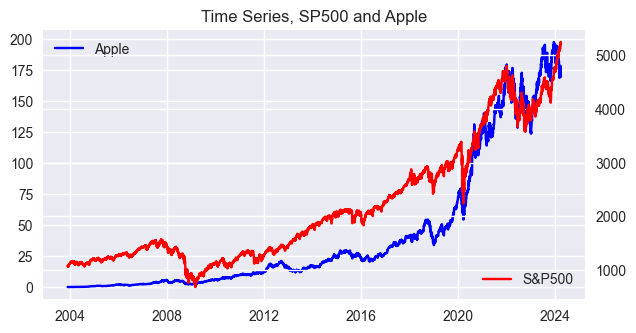

In [ ]:
data_=data
data_["Date"]= pd.to_datetime(data_["Date"])
data_= data_.set_index("Date")

fig, ax= plt.subplots()
plt.rcParams["figure.figsize"] = [7.00, 3.5]
#ax.plot(data_.index, data_["DAX in USD"], color= "blue", label= "in USD DAX")
ax.plot(data_.index, data_["AAPL"], color= "blue", label= "Apple")
ax2= ax.twinx()
ax2.plot(data_.index, data_["S&P 500 in USD"], color= "red", label= "S&P500")

ax.legend(loc="upper left")
ax2.legend(loc= "lower right")
#plt.legend()

#plt.title("Time Series, SP500 and DAX")
plt.title("Time Series, SP500 and Apple")
plt.grid(True)

plt.show()  


Regime Change Graph

In [ ]:
data_= data
data_["S&P_rebalanced"]= data_["S&P 500 in USD"]/data_["S&P 500 in USD"][0] * 100
data_["NVDA_rebalanced"]= data_["NVDA"]/data_["NVDA"][0] * 100
data_

#data_["S&P_Crises"]= data["Regime_SPvsDAX"] * 500

# This line labels the crises according to Turbulent for sp index values
#data_["S&P_Crises"]= data["Regime_vol_ret"] * 500

# This line labels the crises according to HMM on volatility of return
#data_["S&P_Crises"]= data["Regime_SPvsDAX_ret_vol"] * 500

# This line labels the crises according to Turbulent MEthod for sp's return
#data_["S&P_Crises"]= data["Regime_Turbulent_ret"] * 500

#data_["S&P_Crises"]= data["Regime_SP_ret_vol"] * 500

# This is NVDA turbulance regimes
data_["NVDA_Turb"]= data["Regime_NVDA_ret_vol"] * 500


In [ ]:
#data_["S&P_Crises"].to_csv("data/data_.csv")

/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_701/3969386036.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn")


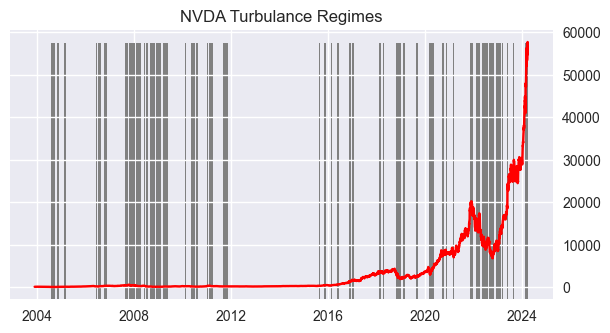

In [ ]:
fig, ax= plt.subplots()
plt.style.use("seaborn")
plt.rcParams["figure.figsize"] = [7.00, 3.5]
data_["Date"]= pd.to_datetime(data_["Date"])
data_= data_.set_index("Date")
#ax.bar(x=data_.index, height=data_["S&P_Crises"], width=1.5, color= "gray")
#ax.bar(x=data_.index, height=data["Regime_vol_ret"] *500, width=1.5, color= "gray")
#ax.bar(x=data_.index, height=data["Regime_SPvsDAX_ret_vol"]* 500, width=1.5, color= "gray")
#ax.bar(x=data_.index, height=data["Regime_SP_ret_vol"]* 500, width=1.5, color= "gray")
#ax.bar(x=data_.index, height=data["SPvsDAX_Turbulent_index_ret"]* 500, width=1.5, color= "gray")
# Regime detection using the forecasted colatility by garch model
#ax.bar(x=data_.index, height=data["Regime_SPvsDAX_garch_vol"]* 500, width=1.5, color= "gray")
# Regime detection for NVDA turbulances
ax.bar(x=data_.index, height=data["Regime_NVDA_ret_vol"]* 500, width=1.5, color= "gray")
ax2= ax.twinx()
#ax2.plot(data_.index, data_["S&P_rebalanced"], color= "red")
ax2.plot(data_.index, data_["NVDA_rebalanced"], color= "red")
ax.axes.get_yaxis().set_visible(False)
#data_["Regime_vol_ret"].plot(kind="bar", color="red")
#data_["S&P_rebalanced"].plot(kind="line", color="blue")
#plt.title("S&P500 Turbulence Detection")
plt.title("NVDA Turbulance Regimes")
plt.show()  

# Estimated Parameters

Parameters Estimated for S&P vs AAPL

In [49]:

M= np.array([[-2.9755, 0.5001], [0.2662, -1.2210]])
#M= np.array([[0, 0], [0, 0]])
Q= np.array([[-0.0216, -0.1560], [0.1106, 0.0292]])
#Q= np.array([[0, 0], [0, 0]])
beta= 6 #beta=5.6347
y_0= np.array([6.9755,-1.1141])
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho= np.array([0.1252, -0.2814])
#rho= np.array([0, 0])
Sigma_inf_normal= np.array([[0.0150, 0.0176], [0.0176, 0.0653]])
Sigma_inf_total= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat= Sig_hat_total_vs_normal
#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0= Sigma_inf_normal


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw= Sigma_inf_normal


# risk free rate
r=0.02

lambda_0= 1.0657
#lambda_0= 0.0001
lambda_1= 3.76497
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
daily_transmat= np.array([[0.99581131, 0.00418869],
       [0.01479807, 0.98520193]])


#mu= np.array([0.1135, 0.4572])
mu= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)


K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 5000
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)

In [64]:
#Estimated Wishart for Total Data for SP500 vs APPLE


M= np.array([[-3.8393, 0.7024], [0.2519, -1.9265]]) #
#M= np.array([[0, 0], [0, 0]])
Q= np.array([[-0.0243, -0.1491], [0.1085, 0.0321]]) #
#Q= np.array([[0, 0], [0, 0]])
beta= 11 #beta=10.9151 #
y_0= np.array([6.9755,-1.1141]) #
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho= np.array([0.1453, -0.1968])  #
#rho= np.array([0, 0])
Sigma_inf_normal= np.array([[0.0219, 0.0235], [0.0235, 0.0745]]) #
Sigma_inf_total= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat= Sig_hat_total_vs_normal
#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0= Sigma_inf_normal


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw= Sigma_inf_normal


# risk free rate
r=0.02

lambda_0= 1.0657
#lambda_0= 0.0001
lambda_1= 3.76497
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
daily_transmat= np.array([[0.99581131, 0.00418869],
       [0.01479807, 0.98520193]])


#mu= np.array([0.1135, 0.4572])
mu= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)


K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 5000
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)


New Estimation for SP500-AAPL Feb 14

In [2]:
# Estimation on SP500-AAPL on normal period data
M_N= np.array([[-1.0202, 0.1418], [1.3596, -0.8224]]) # estimation Fb 14
#M= np.array([[0, 0], [0, 0]])
Q_N= np.array([[0.0689, 0], [0, 0.1173]]) # estimation Fb 14
#Q= np.array([[0, 0], [0, 0]])
beta_N= 7.5504 # estimation Fb 14
y_0= np.array([6.9755,-1.1141])
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho_N= np.array([-0.5499, -0.1930]) # estimation Fb 14
#rho= np.array([0, 0])
Sigma_inf_normal_N= np.array([[0.0208, 0.0232], [0.0232, 0.1014]]) # estimation Fb 14
Sigma_inf_total= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal_N)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat

#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0_N= Sigma_inf_normal_N


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw_N= Sigma_inf_normal_N


# risk free rate
r=0.04

lambda_0= 1.0657
#lambda_0= 0.0001
lambda_1= 3.76497
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
daily_transmat= np.array([[0.99581131, 0.00418869],
       [0.01479807, 0.98520193]])


#mu= np.array([0.1031, 0.4065]) # estimation Fb 14
mu_N= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)
sighat_N= (lambda_0 + lambda_1)/lambda_1 * Sig_hat_total_vs_normal

K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 100
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)

Lambda= np.array([[1, 0],
       [0, 1]])

M_tild_N= M_N - Q_N @ Lambda

In [3]:
#Estimated Wishart for Total Data for SP500 vs APPLE


M_T= np.array([[-1.0027, 0.2022], [1.5593, -0.9996]]) # Feb 12 coef= 10 &  Feb 13 coef= 10
#M= np.array([[0, 0], [0, 0]])
Q_T= np.array([[0.0769, 0], [0, 0.0992]]) ## Feb 12 coef= 10 &  Feb 13 coef= 10
#Q= np.array([[0, 0], [0, 0]])
beta_T= 9.7316 # Feb 12 coef= 10 &  Feb 13 coef= 10
y_0= np.array([6.9755,-1.1141]) #
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho_T= np.array([-0.5055, -0.2170]) # Feb 12 coef= 10 &  Feb 13 coef= 10
#rho= np.array([0, 0])
Sigma_inf_normal_T= np.array([[0.03669, 0.03966], [0.03966, 0.10977]]) # Feb 12 coef= 10 &  Feb 13 coef= 10
Sigma_inf_total= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal_T)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat_T= Sig_hat_total_vs_normal
#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0_T= Sigma_inf_normal_T


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw_T= Sigma_inf_normal_T


# risk free rate
r=0.04

lambda_0= 1.0657
#lambda_0= 0.0001
lambda_1= 3.76497
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
daily_transmat= np.array([[0.99581131, 0.00418869],
       [0.01479807, 0.98520193]])


#mu= np.array([0.0799, 0.3151]) #Feb 11, Feb 12 coef=10 &  Feb 13 coef= 10
mu_T= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)


K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 100
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)

M_tild_T= M_T - Q_T @ Lambda

Parameters Estimated for GOOG vs INTC

In [2]:
# Estimation on GOOGLE-INTEL on normal period data
M_N= np.array([[-1.0007, -0.8390], [1.7223, -1.0006]]) # Est Feb 22
#M= np.array([[0, 0], [0, 0]])
Q_N= np.array([[0.1521, 0], [0, 0.0923]]) # Est Feb 22
#Q= np.array([[0, 0], [0, 0]])
beta_N= 9.9356  # Initial Point Feb 22
y_0= np.array([0.9124,2.5416]) # Est Feb 22
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho_N= np.array([-0.4081, -0.1274]) # Est Feb 22
#rho= np.array([0, 0])
Sigma_inf_normal_N= np.array([[0.0870, 0.0332], [0.0332, 0.0995]]) # Est Feb 22
Sigma_inf_hist_N= np.array([[0.0877, 0.03346], [0.03346, 0.10026]])
Sigma_inf_total= np.array([[0.0927, 0.0424], [0.0424, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal_N)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
#sighat_N= Sig_hat_total_vs_normal
#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0_N= Sigma_inf_normal_N


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw_N= Sigma_inf_normal_N


# risk free rate
r=0.04

lambda_0= 44.003
#lambda_0= 0.0001
lambda_1= 128.685
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
#daily_transmat= np.array([[0.99581131, 0.00418869],[0.01479807, 0.98520193]])


#mu= np.array([0.2207, 0.0349])
mu_N= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)

sighat_N= (lambda_0 + lambda_1)/lambda_1 * Sig_hat_total_vs_normal

K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 5000
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)

Lambda= np.array([[1, 0],
       [0, 1]])

M_tild_N= M_N - Q_N @ Lambda

In [3]:
#Estimated Wishart for Total Data for GOOGLE vs INTEL


M_T= np.array([[-0.9990, -0.4437], [1.4443, -1]]) # Estimation Feb 22
#M= np.array([[0, 0], [0, 0]])
Q_T= np.array([[0.1494, 0], [0, 0.0995]]) # Estimation Feb 22
#Q= np.array([[0, 0], [0, 0]])
beta_T= 9.9110 # Initial point Feb 22
y_0= np.array([0.9124,2.5416]) # Est Feb 22
#y_0_0= np.array([0,0])
y_0_0= np.log(np.array([5, 4]))
#y_0_0= np.log(np.array([2, 1]))
#y_0_0= np.log(np.array([100, 101]))
#y_0_0= np.log(np.array([101, 100]))
#y_0_0= np.log(np.array([51, 50]))
rho_T= np.array([-0.3860, -0.1874]) # Estimation Feb 22
#rho= np.array([0, 0])
Sigma_inf_normal_T= np.array([[0.0920, 0.0421], [0.0421, 0.1099]])  # Estimation Feb 22
Sigma_inf_total= np.array([[0.0927, 0.0424], [0.0424, 0.1107]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal_T)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat_T= Sig_hat_total_vs_normal
#sighat= 1/2 * (Sig_hat_total_vs_normal + np.transpose(Sig_hat_total_vs_normal))
#sighat= 0.001 * Sig_hat_total_vs_normal
Sigma_0_T= Sigma_inf_normal_T


T= 1
#T= 1/12
#T=1/52
t_= 0

tau= T - t_
T_t= T - t_


# Matrix sigma^wishart 
sigmaw_T= Sigma_inf_normal_T


# risk free rate
r=0.04

lambda_0= 44.003
#lambda_0= 0.0001
lambda_1= 128.685
#lambda_01 and lambda_10
lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)
#daily_transmat= np.array([[0.99581131, 0.00418869],[0.01479807, 0.98520193]])


#mu= np.array([0.2090, 0.0330])
mu_T= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)


K= 0.5


# S_1 - S_2 -K
#eps_1= -2 * 1j
#eps_2= 0.5 * 1j
eps_1= -3 * 1j
eps_2= 1 * 1j
#eps_1= -1.5 * 1j
#eps_2= 0.25 * 1j

# S_2 - S_1 -K
#eps_1= 0.5 * 1j
#eps_2= -2 * 1j

#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.03

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value

# Monte Carlo Parameters
N= 252
#N= 5 * 8
#N=21*8
paths= 5000
#M_paths= 100
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)
#dt= (T - t_) / N
#np.random.seed(seed=42)

M_tild_T= M_T - Q_T @ Lambda

# Characteristic function for Shifted Wishart Process

In [49]:
# Characteristic function for Shifted Wishart Process
def Phi_SW(tau, omega, y_0, sigmaw, sighat, M, Q, rho, beta, mu):
    omega_diag= np.asmatrix(np.diag(omega))
    omega= np.matrix.transpose(np.asmatrix(omega))
    rho= np.matrix.transpose(np.asmatrix(rho))
    # omega, rho  and mu are now matrices of shape (2,1)
    def split(array, nrows, ncols):
        """Split a matrix into sub-matrices."""
        r, h = array.shape
        return  (array.reshape(h//nrows, nrows, -1, ncols)
                    .swapaxes(1, 2)
                    .reshape(-1, nrows, ncols))
    def Lambda(tau, omega):
        lambda_11= M + 1j* (np.matrix.transpose(Q) @ (rho @ np.matrix.transpose(omega)))
        lambda_12= -2 * ( np.matrix.transpose(Q) @ Q)
        lambda_21= - 1j* 1/2 * omega_diag - 1/2 * (omega @ np.matrix.transpose(omega))
        lambda_22= - np.matrix.transpose(M)- 1j*  ((omega @ np.matrix.transpose(rho)) @ Q)
        lambd= np.asmatrix(np.block([[lambda_11, lambda_12], [lambda_21,lambda_22]]))
        #output= np.asmatrix(scipy.linalg.expm(tau * lambd))
        output= scipy.linalg.expm(tau * lambd)
        return output
    def A(tau, omega):
        Lambd= Lambda(tau, omega)
        Lambda_11, Lambda_12, Lambda_21, Lambda_22= split(Lambd,2,2)
        Lambda_11, Lambda_12, Lambda_21, Lambda_22= np.asmatrix(Lambda_11), np.asmatrix(Lambda_12), np.asmatrix(Lambda_21), np.asmatrix(Lambda_22)
        output= np.linalg.inv(Lambda_22) @ Lambda_21
        return output
    def c(tau,omega, mu):
        Lambd= Lambda(tau, omega)
        Lambda_11, Lambda_12, Lambda_21, Lambda_22= split(Lambd,2,2)
        Lambda_11, Lambda_12, Lambda_21, Lambda_22= np.asmatrix(Lambda_11), np.asmatrix(Lambda_12), np.asmatrix(Lambda_21), np.asmatrix(Lambda_22)
        mu= np.matrix.transpose(np.asmatrix(mu))
        part_1= scipy.linalg.logm(Lambda_22) + tau * np.matrix.transpose(M) + 1j * tau * ((omega @ np.matrix.transpose(rho)) @ Q) 
        part_2= tau * np.matrix.trace(1j * (mu @ np.matrix.transpose(omega)))
        output=  - beta/2 * np.matrix.trace(part_1) + part_2
        return output
    AB= A(tau, omega)
    y_0= np.matrix.transpose(np.asmatrix(y_0))
    diag_sighat= np.matrix.transpose(np.asmatrix(np.diagonal(sighat)))
    part_W=  1j * np.matrix.transpose(omega) @ y_0 + np.matrix.trace(AB @ sigmaw) + c(tau,omega, mu)
    part_SW=  tau * 1j* (np.matrix.transpose(omega) @ (- 1/2 * diag_sighat)) - 1/2 * tau * ((np.matrix.transpose(omega) @ sighat) @ omega) 
    output= (part_W + part_SW)[(0,0)]
    output= np.exp(output)
    return output

#Characteristic function for Wishart Process
def Phi_W(tau, omega, y_0, sigmaw, M, Q, rho, beta, mu):
    sighat_= np.array([[0, 0], [0, 0]])
    return Phi_SW(tau, omega, y_0, sigmaw, sighat_, M, Q, rho, beta, mu)

#integral function
def integral_func(func, x_1, x_2, y_1, y_2, resolution= integral_resolution):
    return scipy.integrate.dblquad(func, omega_lb, omega_ub, omega_lb, omega_ub)[0]
    result= 0
    for i in range (int((x_2 - x_1)/resolution)):
        for j in range(int((y_2 - y_1)/resolution)):
            u= x_1 + (i+1/2) * resolution
            v= y_1 + (j+1/2) * resolution
            result += func(u,v) * resolution**2
    #return result

# Option Valuation by formula

In [50]:
# Characteristic function for Markov Modulated Shifted Wishart Process
import scipy.integrate


def vartet(w):
    eta_1= (w+lambda_10 - lambda_01)/2 + np.sqrt((w+lambda_10 - lambda_01)**2 /4 + lambda_10 * lambda_01)
    eta_2= (w+lambda_10 - lambda_01)/2 - np.sqrt((w+lambda_10 - lambda_01)**2 /4 + lambda_10 * lambda_01)
    vartet_0= np.exp(- (eta_1 +lambda_01)*tau) * (eta_2 +lambda_01 - (eta_1 +lambda_01) * np.exp(- (eta_2-eta_1)*tau))/ (eta_2-eta_1)
    vartet_1= 1/lambda_01 * np.exp(- (eta_1 +lambda_01)*tau) * (eta_2*(eta_1 +lambda_01) * np.exp(- (eta_2-eta_1)*tau) - eta_1 *(eta_2+lambda_01))/ (eta_2-eta_1)
    return p * vartet_0+ (1-p) * vartet_1
"""
def vartet(w):
    eta_1= (w+lambda_1 - lambda_0)/2 + np.sqrt((w+lambda_1 - lambda_0)**2 /4 + lambda_1 * lambda_0)
    eta_2= (w+lambda_1 - lambda_0)/2 - np.sqrt((w+lambda_1 - lambda_0)**2 /4 + lambda_1 * lambda_0)
    vartet_0= np.exp(- (eta_1 +lambda_0)*tau) * (eta_2 +lambda_0 - (eta_1 +lambda_0) * np.exp(- (eta_2-eta_1)*tau))/ (eta_2-eta_1)
    vartet_1= 1/lambda_0 * np.exp(- (eta_1 +lambda_0)*tau) * (eta_2*(eta_1 +lambda_0) * np.exp(- (eta_2-eta_1)*tau) - eta_1 *(eta_2+lambda_0))/ (eta_2-eta_1)
    return p * vartet_0+ (1-p) * vartet_1
"""

def Phi_MMSW(tau, omega, y_0, sigmaw, M, Q, rho, beta, sighat, mu):
    Phi_0= Phi_W(tau, omega, y_0, sigmaw, M, Q, rho, beta, mu)
    Phi_1= Phi_SW(tau, omega, y_0, sigmaw, sighat, M, Q, rho, beta, mu)
    return Phi_0 * vartet(np.log(Phi_0 / Phi_1))

# The function P_hat
def K_(K,omega):
    # for K=1 this function return 1
    #return 1
    return np.exp(np.log(K) * (1- 1j * (omega[0] + omega[1])))

"""
#1-d integral function
def integral_func_1d(func, x_1, x_2, omega, resolution= integral_resolution_I):
    real_part, _= scipy.integrate.quad(lambda x: np.real(func(omega, x)),x_1, x_2 )
    complex_part, _= scipy.integrate.quad(lambda x: np.imag(func(omega, x)),x_1, x_2 )
    return complex(real_part,complex_part)
    result= 0
    for i in range (int((x_2 - x_1)/resolution)):
            u= x_1 + (i+1/2) * resolution
            result += func(omega,u) * resolution
    return result
def I(x, omega):
    def func(omega,t):
        return t**(omega[0]-1) * (1-t)**(omega[1]-1)
        #return np.exp(np.log(t)* (omega[0]-1) + np.log(1-t) * (omega[1]-1))
    inc_beta_value= integral_func_1d(func, 0, x, omega)
    comp_beta= scipy.special.gamma(omega[0]) * scipy.special.gamma(omega[1])/ scipy.special.gamma(omega[0] + omega[1])
    return inc_beta_value/ comp_beta
def I_(K, omega):
    omega_= np.array([(1j* (omega[0] + omega[1])-1), (- 1j * omega[1] + 2)])
    return I(K, omega_)
"""

def gamma_term(omega):
    # in our paper
    #return scipy.special.gamma(1j * (omega[0] + omega[1])-1) * scipy.special.gamma(- 1j* omega[0])/scipy.special.gamma(1j * omega[1] + 1)
    # As in Hurd's paper
    return scipy.special.gamma(1j * (omega[0] + omega[1])-1) * scipy.special.gamma(- 1j* omega[1])/scipy.special.gamma(1j * omega[0] + 1)
#counter_nan= 0
#counter_total=0
def P_hat(K, omega):
    #output= K_(K,omega) * I_(K, omega) * gamma_term(omega)
    output= K_(K,omega) * gamma_term(omega)
    # for K=1 K_ and I terms are equal to 1
    #output= gamma_term(omega)
    #counter_total += 1
    return output

#Option Valuation function for Wishart Process
def V_W(tau,K, sigmaw, M, Q, rho, beta, y_0, mu):
    def func (omega_1,omega_2):
        omega= np.array([omega_1+eps_1, omega_2+eps_2])
        #return P_hat(K, omega) * Phi_W(tau, omega, y_0, M, Q, rho, beta, mu)
        return np.real(P_hat(K, omega) * Phi_W(tau, omega, y_0, sigmaw, M, Q, rho, beta, mu))
    output= (np.exp(-r *tau) /(4* np.pi**2)) * integral_func(func, omega_lb,omega_ub,omega_lb,omega_ub)
    return output

# Option Valuation function for Shifted Wishart Process
def V_SW(tau,K, sigmaw, M, Q, rho, beta, sighat, y_0, mu):
    def func (omega_1,omega_2):
        omega= np.array([omega_1+eps_1, omega_2+eps_2])
        return np.real(P_hat(K, omega) * Phi_SW(tau, omega, y_0, sigmaw, sighat, M, Q, rho, beta, mu))
    output= (np.exp(-r *tau) /(4* np.pi**2)) * integral_func(func, omega_lb,omega_ub,omega_lb,omega_ub)
    return output

#Option Valuation function for Markov Modulated Shifted Wishart Process
def V_MMSW(tau,K, sigmaw, M, Q, rho, beta, sighat, y_0, mu):
    def func (omega_1,omega_2):
        omega= np.array([omega_1+eps_1, omega_2+eps_2])
        return np.real(P_hat(K, omega) * Phi_MMSW(tau, omega, y_0, sigmaw, M, Q, rho, beta, sighat, mu))
    output= (np.exp(-r *tau) /(4* np.pi**2)) * integral_func(func, omega_lb,omega_ub,omega_lb,omega_ub)
    return output 

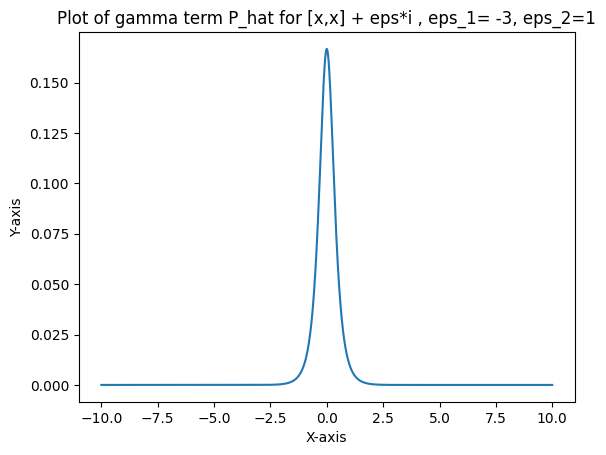

In [105]:
def fun_valuation(x):
  omega= np.array([x,x]) + np.array([eps_1, eps_2])
  #omega= np.array([x,x]) 
  #return np.abs(P_hat(K, omega))
  return P_hat(K, omega)
  #return I_(K, omega)
# Set the range of x-values for plotting (adjust as needed)
x_min = -10
x_max = 10
num_points = 10000

# Create an array of x-values
x_values = np.linspace(x_min, x_max, num_points)

# Calculate the corresponding y-values using the function
#y_values = fun_valuation(x_values)
y_values=[]

for x in x_values:
  y_values.append(fun_valuation(x))

# Plot the x-y values
plt.plot(x_values, y_values)

# Set plot labels and title (customize as needed)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Plot of gamma term P_hat for [x,x] + eps*i , eps_1= -3, eps_2=1")

# Show the plot
plt.show()


In [10]:
K=0.5
tau=1
V_WP= V_W(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
print("V_WP: ", V_WP.real.round(6))
V_SP= V_SW(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
print("V_SP: ", V_SP.real.round(6))
V_MM= V_MMSW(tau,K, sigmaw_N, M_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_N)
print("V_MMSW: ", V_MM.real.round(6))
print("V_WP: ", V_WP.real.round(6), "V_SW: ", V_SP.real.round(6), "V_MMSW: ", V_MM.real.round(6))

V_WP:  0.745429
V_SP:  0.747048
V_MMSW:  0.76174
V_WP:  0.745429 V_SW:  0.747048 V_MMSW:  0.76174


In [77]:
K_list= [0.5, 1, 1.5]
tau= 1
for K in K_list:
    print("K := ", K)
    #V_WP= V_W(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
    V_WP= V_W(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
    print("V_WP: ", V_WP.real.round(6))
    #V_SP= V_SW(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
    V_SP= V_SW(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
    print("V_SP: ", V_SP.real.round(6))
    #V_MM= V_MMSW(tau,K, sigmaw_N, M_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_N)
    V_MM= V_MMSW(tau,K, sigmaw_N, M_tild_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_N)
    print("V_MMSW: ", V_MM.real.round(6))
    print("V_WP: ", V_WP.real.round(6), "V_SW: ", V_SP.real.round(6), "V_MMSW: ", V_MM.real.round(6))

K :=  0.5
V_WP:  0.887004
V_SP:  0.889236
V_MMSW:  0.892839
V_WP:  0.887004 V_SW:  0.889236 V_MMSW:  0.892839
K :=  1
V_WP:  0.610513
V_SP:  0.612959
V_MMSW:  0.61646
V_WP:  0.610513 V_SW:  0.612959 V_MMSW:  0.61646
K :=  1.5
V_WP:  0.399428
V_SP:  0.401859
V_MMSW:  0.404566
V_WP:  0.399428 V_SW:  0.401859 V_MMSW:  0.404566


Price Surfaces

In [ ]:
#Price Surface for Wishart Process
K_list= np.linspace(0.1, 2, 20)
T_list= np.linspace(1/12, 1, 12)
#K_list= [0.1]
#T_list= [1/12]
Surface_W= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_WP= V_W(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_WP}
        Surface_W= Surface_W.append(new_data, ignore_index=True)
Surface_W.to_csv("New_SPvsAPPLE_Wishart_Surface.csv", index= False)

# Price Surface for Shifted Wishart
Surface_SW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_SP= V_SW(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_SP}
        Surface_SW= Surface_SW.append(new_data, ignore_index=True)
Surface_SW.to_csv("SPvsAPPLE_Shifted_Wishart_Surface.csv", index= False)

# Price Surface for MMSW 
Surface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_MM= V_MMSW(tau,K, sigmaw_N, M_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_MM}
        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)
Surface_MMSW.to_csv("SPvsAPPLE_MMS_Wishart_Surface.csv", index= False)

'\n# Price Surface for Shifted Wishart\nSurface_SW= pd.DataFrame(columns= ["K", "T", "Price"])\nfor K in K_list:\n    for T in T_list:\n        tau= T - t_\n        V_SP= V_SW(t_,K, M, Q, rho, beta, sighat, y_0_0, mu)\n        new_data= {"K": K, "T": T, "Price": V_SP}\n        Surface_SW= Surface_SW.append(new_data, ignore_index=True)\nSurface_SW.to_csv("SPvsAPPLE_Shifted_Wishart_Surface.csv", index= False)\n\n# Price Surface for MMSW \nSurface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])\nfor K in K_list:\n    for T in T_list:\n        tau= T - t_\n        V_MM= V_MMSW(t_,K, M, Q, rho, beta, sighat, y_0_0, mu)\n        new_data= {"K": K, "T": T, "Price": V_MM}\n        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)\nSurface_MMSW.to_csv("SPvsAPPLE_MMS_Wishart_Surface.csv", index= False)\n'

In [ ]:
#Price Surface for Wishart Process in Q measure
K_list= np.linspace(0.1, 2, 20)
T_list= np.linspace(1/12, 1, 12)
#K_list= [0.1]
#T_list= [1/12]
Surface_W= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_WP= V_W(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_WP}
        Surface_W= Surface_W.append(new_data, ignore_index=True)
Surface_W.to_csv("New_SPvsAPPLE_Wishart_Surface_tild.csv", index= False)

# Price Surface for Shifted Wishart
Surface_SW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_SP= V_SW(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_SP}
        Surface_SW= Surface_SW.append(new_data, ignore_index=True)
Surface_SW.to_csv("SPvsAPPLE_Shifted_Wishart_Surface_tild.csv", index= False)

# Price Surface for MMSW 
Surface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_MM= V_MMSW(tau,K, sigmaw_N, M_tild_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_MM}
        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)
Surface_MMSW.to_csv("SPvsAPPLE_MMS_Wishart_Surface_tild.csv", index= False)

# Estimations for NVIDIA-INTEL pair

Old Estimation

In [3]:
# Parameters for NVIDIA vs INTEL

M= np.array([[-1.4379, 1.2629], [0.1591, -3.7249]])
Q= np.array([[-0.0230, -0.1499], [0.1079, 0.0326]])
beta= 15 #beta=15.0991
y_0= np.array([0.4982,2.9835])
y_0_0= np.log(np.array([5, 4]))
rho= np.array([0.1573, -0.1010])
#rho= np.array([0, 0])
Sigma_inf_normal= np.array([[0.0974, 0.0382], [0.0382, 0.0606]])
# To estimate
Sigma_inf_total= np.array([[0.2499, 0.0842], [0.0842, 0.1031]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat= Sig_hat_total_vs_normal
#sighat= np.array([[0.0001, 0.0001], [0.0001, 0.0001]])

Sigma_0= Sigma_inf_normal

T= 1
t_= 0
tau= T- t_
T_t= T- t_

# Matrix sigma^wishart 
sigmaw= Sigma_inf_normal

# risk free rate
r=0.02

lambda_0= 2.7019
lambda_1= 5.0988

lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)

#mu= np.array([0.5797, 0.1167])
mu= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)

K= 0.5

eps_1= -3 * 1j
eps_2= 1 * 1j
#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.005

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value


# Monte Carlo Parameters
#N= 252
#N= 252 * 8
#N=21*10
N=5*8
paths= 2000
#paths= 2000
M_paths= 30
T_vec, dt = np.linspace(t_, T, N, retstep=True)

#np.random.seed(seed=42)

In [68]:
# Estimated Wishart on Total Data for NVIDIA vs INTEL

M= np.array([[-1.4263, 1.7276], [0.1493, -3.3176]]) #
Q= np.array([[-0.0241, -0.1542], [0.1089, 0.0335]]) #
beta= 16 #beta=15.9860 #
y_0= np.array([0.4982,2.9835]) #
y_0_0= np.log(np.array([5, 4]))
rho= np.array([0.1687, -0.1242]) #
#rho= np.array([0, 0])
Sigma_inf_normal= np.array([[0.1464, 0.0633], [0.0633, 0.0930]]) #
# To estimate
Sigma_inf_total= np.array([[0.2499, 0.0842], [0.0842, 0.1031]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal= np.subtract(Sigma_inf_total, Sigma_inf_normal)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat= Sig_hat_total_vs_normal
#sighat= np.array([[0.0001, 0.0001], [0.0001, 0.0001]])

Sigma_0= Sigma_inf_normal

T= 1
t_= 0
tau= T- t_
T_t= T- t_

# Matrix sigma^wishart 
sigmaw= Sigma_inf_normal

# risk free rate
r=0.02

lambda_0= 2.7019
lambda_1= 5.0988

lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)

#mu= np.array([0.5797, 0.1167])
mu= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)

K= 0.5

eps_1= -3 * 1j
eps_2= 1 * 1j
#T_= len(data) -1

# integral bounds
omega_lb = - 20
omega_ub = 20
integral_resolution= 0.005

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value


# Monte Carlo Parameters
#N= 252
#N= 252 * 8
#N=21*10
N=5*8
paths= 2000
#paths= 2000
M_paths= 30
T_vec, dt = np.linspace(t_, T, N, retstep=True)

#np.random.seed(seed=42)

New Estimation for NVIDIA-INTEL pair

In [2]:
# Parameters for NVIDIA vs INTEL in Normal Period

#M_N= np.array([[-1.8246, 0.2301], [0.3607, -0.3294]])
M_N= np.array([[-0.8384, -0.1236],  [0.1596, -0.1398]  ])
#Q_N= np.array([[0.2309, 0.0237], [-0.0392, 0.0156]])
Q_N= np.array([[0.2286, 0.0235], [-0.0388, 0.0154]])
beta_N= 7 #beta=6.9267
y_0= np.array([0.4982,2.9835])
y_0_0= np.log(np.array([5, 4]))
#rho_N= np.array([-0.4089, -0.1274])
rho_N= np.array([-0.4049, -0.1285])
#rho= np.array([0, 0])
#Sigma_inf_normal_N= np.array([[0.1091, 0.0394], [0.0394, 0.0516]])
Sigma_inf_normal_N= np.array([[0.2114, 0.0572],  [0.0572, 0.0846] ])
# To estimate
Sigma_inf_total_N= np.array([[0.2460, 0.0668], [0.0668, 0.1138]])

#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat_N= Sig_hat_total_vs_normal_N
#sighat= np.array([[0.0001, 0.0001], [0.0001, 0.0001]])

Sigma_0_N= Sigma_inf_normal_N

T= 1
t_= 0
tau= T- t_
T_t= T- t_

# Matrix sigma^wishart 
sigmaw_N= Sigma_inf_normal_N

# risk free rate
r=0.04

lambda_0= 2.7019
lambda_1= 5.0988

lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)

#mu= np.array([0.5797, 0.1167])
mu_N= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)

K= 0.5

eps_1= -3 * 1j
eps_2= 1 * 1j
#T_= len(data) -1

# integral bounds
omega_lb = - 50
omega_ub = 50
integral_resolution= 0.005

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value


# Monte Carlo Parameters
N= 252
#N= 252 * 8
#N=21*10
#N=5*8
paths= 5000
#paths= 2000
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)

#np.random.seed(seed=42)

Lambda= np.array([[1, 0],
       [0, 1]])

M_tild_N= M_N - Q_N @ Lambda

In [3]:
# Estimated Wishart on Total Data for NVIDIA vs INTEL

#M_T= np.array([[-1.6422, 0.2642], [0.3835, -0.3764]]) #
M_T= np.array([[-0.9108, -0.1232],  [0.2412, -0.2319]  ])
#Q_T= np.array([[0.2271, 0.0248], [-0.0342, 0.0139]]) #
Q_T= np.array([[0.2248, 0.0246], [-0.0339, 0.0138]])
beta_T= 8 #beta=8.4909 #
y_0= np.array([0.4982,2.9835]) #
y_0_0= np.log(np.array([5, 4]))
#rho_T= np.array([-0.3869, -0.1874]) #
rho_T= np.array([-0.3831, -0.1891])
#rho= np.array([0, 0])
#Sigma_inf_normal_T= np.array([[0.1472, 0.0589], [0.0589, 0.0692]]) #
Sigma_inf_normal_T= np.array([[0.2307, 0.0761],  [0.0761, 0.0937]  ])
# To estimate
Sigma_inf_total_T= np.array([[0.2479, 0.0836], [0.0836, 0.1023]])
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat_T= Sig_hat_total_vs_normal_T
#sighat= np.array([[0.0001, 0.0001], [0.0001, 0.0001]])

Sigma_0_T= Sigma_inf_normal_T

T= 1
t_= 0
tau= T- t_
T_t= T- t_

# Matrix sigma^wishart 
sigmaw_T= Sigma_inf_normal_T

# risk free rate
r=0.04

lambda_0= 2.7019
lambda_1= 5.0988

lambda_01= lambda_0 / (lambda_0 + lambda_1)
lambda_10= lambda_1 / (lambda_0 + lambda_1)

#mu= np.array([0.5797, 0.1167])
mu_T= np.array([r, r])

p=lambda_1 / (lambda_0 + lambda_1)

K= 0.5

eps_1= -3 * 1j
eps_2= 1 * 1j
#T_= len(data) -1

# integral bounds
omega_lb = - 50
omega_ub = 50
integral_resolution= 0.005

theta_init= [-13.0661, 1.3101, 1.3101, -32.1887, 0.3073, -0.0135, 0, 0.0998, -0.0378, -0.0961, 9]
#aa=0.6 permitted deviation from the initial value


# Monte Carlo Parameters
N= 252
#N= 252 * 8
#N=21*10
#N=5*8
paths= 5000
#paths= 2000
M_paths= paths
T_vec, dt = np.linspace(t_, T, N, retstep=True)

#np.random.seed(seed=42)

M_tild_T= M_T - Q_T @ Lambda

In [ ]:
#Price Surface for Wishart Process
K_list= np.linspace(0.1, 2, 20)
T_list= np.linspace(1/12, 1, 12)
Surface_W= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_WP= V_W(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_WP}
        Surface_W= Surface_W.append(new_data, ignore_index=True)
    print("K= ", K)
Surface_W.to_csv("New_NVIDIAvsINTEL_Wishart_Surface.csv", index= False)

# Price Surface for Shifted Wishart
Surface_SW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_SP= V_SW(tau,K, sigmaw_T, M_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_SP}
        Surface_SW= Surface_SW.append(new_data, ignore_index=True)
Surface_SW.to_csv("NVIDIAvsINTEL_Shifted_Wishart_Surface.csv", index= False)

# Price Surface for MMSW 
Surface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_MM= V_MMSW(tau,K, sigmaw_N, M_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_MM}
        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)
Surface_MMSW.to_csv("NVIDIAvsINTEL_MMS_Wishart_Surface.csv", index= False)


K=  0.1
K=  0.2
K=  0.3
K=  0.4
K=  0.5
K=  0.6
K=  0.7
K=  0.7999999999999999
K=  0.8999999999999999
K=  0.9999999999999999
K=  1.0999999999999999
K=  1.2
K=  1.3
K=  1.4
K=  1.5
K=  1.5999999999999999
K=  1.7
K=  1.8
K=  1.9
K=  2.0


'\n# Price Surface for Shifted Wishart\nSurface_SW= pd.DataFrame(columns= ["K", "T", "Price"])\nfor K in K_list:\n    for T in T_list:\n        tau= T - t_\n        V_SP= V_SW(t_,K, M, Q, rho, beta, sighat, y_0_0, mu)\n        new_data= {"K": K, "T": T, "Price": V_SP}\n        Surface_SW= Surface_SW.append(new_data, ignore_index=True)\nSurface_SW.to_csv("NVIDIAvsINTEL_Shifted_Wishart_Surface.csv", index= False)\n\n# Price Surface for MMSW \nSurface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])\nfor K in K_list:\n    for T in T_list:\n        tau= T - t_\n        V_MM= V_MMSW(t_,K, M, Q, rho, beta, sighat, y_0_0, mu)\n        new_data= {"K": K, "T": T, "Price": V_MM}\n        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)\nSurface_MMSW.to_csv("NVIDIAvsINTEL_MMS_Wishart_Surface.csv", index= False)\n'

In [ ]:
#Price Surface for Wishart Process in Q measure
K_list= np.linspace(0.1, 2, 20)
T_list= np.linspace(1/12, 1, 12)
Surface_W= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_WP= V_W(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_WP}
        Surface_W= Surface_W.append(new_data, ignore_index=True)
    print("K= ", K)
Surface_W.to_csv("New_NVIDIAvsINTEL_Wishart_Surface_tild.csv", index= False)

# Price Surface for Shifted Wishart
Surface_SW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_SP= V_SW(tau,K, sigmaw_T, M_tild_T, Q_T, rho_T, beta_T, sighat_T, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_SP}
        Surface_SW= Surface_SW.append(new_data, ignore_index=True)
Surface_SW.to_csv("NVIDIAvsINTEL_Shifted_Wishart_Surface_tild.csv", index= False)

# Price Surface for MMSW 
Surface_MMSW= pd.DataFrame(columns= ["K", "T", "Price"])
for K in K_list:
    for T in T_list:
        tau= T - t_
        V_MM= V_MMSW(tau,K, sigmaw_N, M_tild_N, Q_N, rho_N, beta_N, sighat_N, y_0_0, mu_T)
        new_data= {"K": K, "T": T, "Price": V_MM}
        Surface_MMSW= Surface_MMSW.append(new_data, ignore_index=True)
Surface_MMSW.to_csv("NVIDIAvsINTEL_MMS_Wishart_Surface_tild.csv", index= False)

# Monte Carlo Simulation for generating three matrix processes

Choosing the Model

In [4]:
# For Wishart and Shifted Wishart run only this cell
M, Q, beta, rho, mu, sigmaw, sighat, Sigma_0= M_T, Q_T, beta_T, rho_T, mu_T, sigmaw_T, sighat_T, Sigma_0_T # Lambda=0
#M, Q, beta, rho, mu, sigmaw, sighat, Sigma_0= M_tild_T, Q_T, beta_T, rho_T, mu_T, sigmaw_T, sighat_T, Sigma_0_T # Lambda=I

In [7]:
# For Markov Modulated SW process run only this cell
M, Q, beta, rho, mu, sigmaw, sighat, Sigma_0= M_N, Q_N, beta_N, rho_N, mu_N, sigmaw_N, sighat_N, Sigma_0_N # Lambda=0
#M, Q, beta, rho, mu, sigmaw, sighat, Sigma_0= M_tild_N, Q_N, beta_N, rho_N, mu_N, sigmaw_N, sighat_N, Sigma_0_N # Lambda=I

In [8]:
#Wishart Simulation using Euler-Maruyama Simulation
Sigma_EM = np.zeros((N, paths, 2, 2))
Sigma_EM[0,:]= Sigma_0
W = ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 , 2))
for t in range(0,N-1):
    for j in range(paths):
        sqrt_Sigma_EM= np.real(scipy.linalg.sqrtm(Sigma_EM[t,j]))
        drift=  (beta * (np.matrix.transpose(Q) @ Q) + M @ Sigma_EM[t,j] + Sigma_EM[t,j] @ np.matrix.transpose(M))* dt
        diffusion= np.sqrt(dt) * ( (sqrt_Sigma_EM @ W[t,j]) @ Q +  (np.matrix.transpose(Q) @ np.matrix.transpose(W[t,j])) @ sqrt_Sigma_EM)
        Sigma_EM[t+1,j] = Sigma_EM[t, j] + drift + diffusion


# Ensure all values are symmetric and positive semi-definite
for t in range(N):
    for j in range(paths):
        Sigma_EM[t, j] = (Sigma_EM[t, j] + np.transpose(Sigma_EM[t, j])) / 2  # Symmetrize to avoid numerical issues
        if np.any(np.linalg.eigvals(Sigma_EM[t, j]) <= 0):
            Sigma_EM[t, j] += -1.1 * np.min(np.linalg.eigvals(Sigma_EM[t, j])) * np.eye(2)  # Make positive definite

In [ ]:
# Wishart Simulation using Matrix Valued Ornstein-Uhlenbeck
a= np.matrix.transpose(Q)
b=M
d_= round(beta)
d=2
Y_0_0= scipy.linalg.sqrtm(Sigma_0)
#Y_0_0
Y_0= np.array([[0.11249167, 0.04843164, 0, 0, 0, 0], [0.04843164, 0.25090711, 0, 0, 0, 0]])
Y = np.zeros((N, paths, d, d_))
Y[0, 0,:]= Y_0
Z = ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, d , d_))
for t in range(N-1):
    Y[t+1,:]= Y[t,:] + np.matmul(b,Y[t,:]) * dt + np.sqrt(dt) * np.matmul(a,Z[t,:])
Sigma_OUM = np.zeros((N, paths, 2, 2))
for i in range(N):
    for j in range(paths):
        Sigma_OUM[i,j]= np.matmul(Y[i,j], np.matrix.transpose(Y[i,j]))

In [215]:
# Wishart Simulation using Milstein Method

import scipy.stats as ss
import scipy.linalg

# Initialization
#N = 100  # number of time steps
#paths = 10  # number of simulation paths
#dt = 0.01  # time step size
Sigma_MM = np.zeros((N, paths, 2, 2))
Sigma_MM[0, :] = Sigma_0  # initial condition
W = ss.norm.rvs(size=(N - 1, paths, 2, 2))  # Brownian increments
#beta = 0.1  # just as an example
#Q = np.array([[1, 0], [0, 1]])  # just as an example
#M = np.array([[0.1, 0], [0, 0.1]])  # just as an example

for t in range(N - 1):
    for j in range(paths):
        sqrt_Sigma = np.real(scipy.linalg.sqrtm(Sigma_MM[t, j]))
        dW = W[t, j]
        # Euler-Maruyama part
        drift = (beta * (np.transpose(Q) @ Q)  + M @ Sigma_MM[t, j]  + Sigma_MM[t, j] @ np.transpose(M)) * dt
        diffusion = np.sqrt(dt) * ( (sqrt_Sigma @ dW) @ Q + (np.transpose(Q) @ np.transpose(dW)) @ sqrt_Sigma)
        
        # Milstein correction (for systems similar to GBM, you'd typically include terms that adjust for second-order effects)
        # This example does not include these corrections as they need to be tailored to the specific dynamics of your system
        # Please adjust or compute the necessary second partial derivatives if needed
        MM_corr= 0.5 * np.trace(diffusion/np.sqrt(dt) @ (diffusion @ dW - dW @ diffusion)) * dt
        
        Sigma_MM[t + 1, j] = Sigma_MM[t, j] + drift + diffusion + MM_corr

# Ensure all values are positive semi-definite
for t in range(N):
    for j in range(paths):
        Sigma_MM[t, j] = (Sigma_MM[t, j] + np.transpose(Sigma_MM[t, j])) / 2  # Symmetrize to avoid numerical issues
        if np.any(np.linalg.eigvals(Sigma_MM[t, j]) <= 0):
            Sigma_MM[t, j] += -1.1 * np.min(np.linalg.eigvals(Sigma_MM[t, j])) * np.eye(2)  # Make positive definite


In [6]:
# Choosing the simulation of the Wishart Process

#Sigma_WP= Sigma_OUM
Sigma_WP= Sigma_EM
#Sigma_WP= Sigma_MM

In [10]:
# Simulation of Shifted Wishart Process
Sigma_SW= np.zeros((N, paths, 2, 2))
for i in range(N):
    Sigma_SW[i,:]= sighat + Sigma_WP[i,:]

In [9]:
# Simulation of MArkov Modulated Shifted Wishart Process
#p=0.5
class MarkovRegimeChange:
  """
  Simulates a Markov regime change process with two regimes.

  Attributes:
    transition_matrix (np.array): Transition probability matrix.
    initial_state (int): Initial state of the process (0 or 1).
    num_steps (int): Number of steps to simulate.
  """

  def __init__(self, transition_matrix, initial_state, num_steps):
    """
    Initializes the Markov regime change process.

    Args:
      transition_matrix (np.array): 2x2 transition probability matrix.
      initial_state (int): Initial state of the process (0 or 1).
      num_steps (int): Number of steps to simulate.
    """
    self.transition_matrix = transition_matrix
    self.initial_state = initial_state
    self.num_steps = num_steps

  def simulate(self):
    """
    Simulates the Markov regime change process.

    Returns:
      np.array: Array of states for each step in the simulation.
    """
    states = np.zeros(self.num_steps, dtype=int)
    states[0] = self.initial_state

    for i in range(1, self.num_steps):
      current_state = states[i-1]
      next_state = np.random.choice(2, p=self.transition_matrix[current_state])
      states[i] = next_state

    return states

# Example usage
#transition_matrix = np.array([[p, 1-p], [1-p, p]])  # Example transition probabilities
transition_matrix = np.array([[1- lambda_01, lambda_01], [lambda_10, 1- lambda_10]])  # Example transition probabilities
#initial_state = 0
num_steps = N

States=[]
for j in range(M_paths):
  initial_state= np.random.choice([0, 1], p=[p, 1-p])
  model = MarkovRegimeChange(transition_matrix, initial_state, num_steps)
  states = model.simulate()
  States.append(states)

#print(states)  # This will print an array of simulated states (0 or 1)

"""
#P = np.array([[p, 1-p],
              [1-p, p]])
#stateChangeHist= np.array([[0.0,  0.0],
#                          [0.0, 0.0]])
#state=np.array([[1.0, 0.0]])
#currentState=0
#stateHist=state
#dfStateHist=pd.DataFrame(state)
#distr_hist = [[0,0,0]]
#seed(4)

# Simulate from multinomial distribution
def simulate_multinomial(vmultinomial):
  r=np.random.uniform(0.0, 1.0)
  CS=np.cumsum(vmultinomial)
  CS=np.insert(CS,0,0)
  m=(np.where(CS<r))[0]
  nextState=m[len(m)-1]
  return nextState

# Generating M_paths paths of markov regime change
States=[]
for j in range(M_paths):
  State= []
  for x in range(N):
    currentRow=np.ma.masked_values((P[currentState]), 0.0)
    nextState=simulate_multinomial(currentRow)
    State.append(nextState)
  States.append(State)
States= np.array(States)
"""
States= np.array(States)
# Generating M_paths * paths paths of MMSW process.


In [12]:
Sigma_WP_= Sigma_EM

In [13]:
Sigma_MMSW= np.zeros((N, paths, 2, 2))
for path in range(paths):
    for t in range(N):
        Sigma_MMSW[t,path,:]= States[path, t]*sighat + Sigma_WP_[t,path]

In [57]:
"""
# Price Simulation for MMS Wishart Process: Simulation of ln_price
ln_P = np.zeros((N, M_paths, paths, 2))
ln_P[0,:]= y_0_0
#ln_P[0,:]= y_0
W_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
W_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))


#B= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
#for mp in range(M_paths):
#    for path in range(paths):
#        for t in range(N-1):
#            W_P= np.sqrt(1- np.matmul(np.transpose(rho), rho)) * B[t,mp,path] + np.matmul(W[t,mp,path], rho)


for mp in range(M_paths):
    for path in range(paths):
        for t in range(N-1):
            
            #try:
            #    #ln_P[t+1, mp, path]= ln_P[t, mp, path] + np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W[t, mp, path])
            #    ln_P[t+1, mp, path]= ln_P[t, mp, path] + np.log(dt * mu +  np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat_P[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W_P[t, mp, path]))
            #except RuntimeWarning:
            #    ln_P[t+1, mp, path]= ln_P[t, mp, path]
            
            ln_P[t+1, mp, path]= ln_P[t, mp, path] + np.log(dt * mu +  np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat_P[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W_P[t, mp, path]))
            if ln_P[t+1, mp, path][0]==np.nan or ln_P[t+1, mp, path][1]==np.nan:
                ln_P[t+1, mp, path]= ln_P[t, mp, path]
P= np.exp(ln_P)
"""

'\n# Price Simulation for MMS Wishart Process: Simulation of ln_price\nln_P = np.zeros((N, M_paths, paths, 2))\nln_P[0,:]= y_0_0\n#ln_P[0,:]= y_0\nW_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))\nW_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))\n\n\n#B= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))\n#for mp in range(M_paths):\n#    for path in range(paths):\n#        for t in range(N-1):\n#            W_P= np.sqrt(1- np.matmul(np.transpose(rho), rho)) * B[t,mp,path] + np.matmul(W[t,mp,path], rho)\n\n\nfor mp in range(M_paths):\n    for path in range(paths):\n        for t in range(N-1):\n            \n            #try:\n            #    #ln_P[t+1, mp, path]= ln_P[t, mp, path] + np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W[t, mp, path])\n            #    ln_P[t+1, mp, path]= ln_P[t, mp, path] + np.log(dt * mu +  np.sqrt(dt)* S

In [58]:
"""
from scipy.stats import wishart

def simulate_wishart_prices(num_samples, degrees_of_freedom, sigma):
  
  Simulates prices with a Wishart covariant matrix.

  Args:
      num_samples (int): Number of price samples to simulate.
      degrees_of_freedom (float): Degrees of freedom for the Wishart distribution.
      sigma (np.ndarray): Covariance matrix for the Wishart distribution.

  Returns:
      np.ndarray: Array of simulated prices with shape (num_samples, sigma.shape[0]).
  

  # Check if sigma is a square matrix
  if sigma.shape[0] != sigma.shape[1]:
    raise ValueError("Covariance matrix sigma must be a square matrix.")

  # Simulate random covariance matrices from Wishart distribution
  covariance_matrices = wishart.rvs(degrees_of_freedom, sigma, size=num_samples)

  # Generate random price vectors from a multivariate normal distribution
  # You can customize the mean vector or use a zero-mean vector here
  mean_vector = np.zeros(sigma.shape[0])  # Replace with your desired mean vector
  prices = np.random.multivariate_normal(mean_vector, covariance_matrices, size=num_samples)

  return prices

# Example usage
degrees_of_freedom = 5
sigma = np.array([[1, 0.2], [0.2, 2]])
num_samples = 100

simulated_prices = simulate_wishart_prices(num_samples, degrees_of_freedom, sigma)

print(simulated_prices.shape)  # Output: (100, 2) - 100 samples, 2 dimensions
"""


'\nfrom scipy.stats import wishart\n\ndef simulate_wishart_prices(num_samples, degrees_of_freedom, sigma):\n  \n  Simulates prices with a Wishart covariant matrix.\n\n  Args:\n      num_samples (int): Number of price samples to simulate.\n      degrees_of_freedom (float): Degrees of freedom for the Wishart distribution.\n      sigma (np.ndarray): Covariance matrix for the Wishart distribution.\n\n  Returns:\n      np.ndarray: Array of simulated prices with shape (num_samples, sigma.shape[0]).\n  \n\n  # Check if sigma is a square matrix\n  if sigma.shape[0] != sigma.shape[1]:\n    raise ValueError("Covariance matrix sigma must be a square matrix.")\n\n  # Simulate random covariance matrices from Wishart distribution\n  covariance_matrices = wishart.rvs(degrees_of_freedom, sigma, size=num_samples)\n\n  # Generate random price vectors from a multivariate normal distribution\n  # You can customize the mean vector or use a zero-mean vector here\n  mean_vector = np.zeros(sigma.shape[0])  # 

# Monte Carlo Simulation for Option Pricing and c.f.

In [82]:
# Wishart Process
# Generating prices for Wishart Process
ln_P = np.zeros((N, paths, 2))
ln_P[0,:]= y_0_0
#W_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
#generating W_P with estimated correlations
dB= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
W_P= np.sqrt(1-np.dot(rho, rho)) * dB + W[:,:,] @ rho 
for path in range(paths):
    for t in range(N-1):
        # Here wo do matrix calculations (sqrtm, multiplication) for np.array objects as matrices, a point to check whether it works correctly
        drift= dt * (mu - 0.5 * np.diag(Sigma_WP[t,path]))
        # without - 0.5 * np.diag(Sigma_WP[t,path]) drift as in Da Fonseca model
        #drift= dt * (mu )
        diffusion= np.sqrt(dt) * np.matmul(np.real(scipy.linalg.sqrtm(Sigma_WP[t,path])) , W_P[t,path])
        #ln_P[t+1, path]= ln_P[t, path] + dt * (mu - 0.5 * np.diag(Sigma_WP[t,path])) + np.sqrt(dt) * np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]) , W_P[t,path])
        ln_P[t+1, path]= ln_P[t, path] + drift + diffusion
# Characteristic function of Wishart Process using Expectation
omega_0= np.array([1,1])
omega_1= np.array([3,10])
omega_2= np.array([5,2])
def Phi_W_expect(ln_P,omega):
    values=[]
    for path in range(paths):
        values.append(np.exp(1j * np.dot(omega, ln_P[-1, path, :])))
    return np.mean(values)
print("Characteristic function value for Wishart and  omega: ",omega_0, " = ", Phi_W_expect(ln_P,omega_0))
print("Characteristic function value for Wishart and  omega: ",omega_1, " = ", Phi_W_expect(ln_P,omega_1))
print("Characteristic function value for Wishart and  omega: ",omega_2, " = ", Phi_W_expect(ln_P,omega_2))
# computing the payoffs of the option under Wishart Process
P= np.exp(ln_P)
def payoff(K, price_path) -> float:
    return np.max([price_path[0] - price_path[1] -K, 0])
    #return price_path[0] - price_path[1]
payoffs= []
for path in range(paths):
    payoffs.append(payoff(K, P[-1, path, :]))
    #print(P[-1, path, :])
print("Wishart MC lower 99percent confidence interval", np.percentile(payoffs, 0.5))
print("Wishart MC upper 99percent confidence interval", np.percentile(payoffs, 99.5))
print("Wishart MC lower 95percent confidence interval", np.percentile(payoffs, 2.5))
print("Wishart MC upper 95percent confidence interval", np.percentile(payoffs, 97.5))
W_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
print("Wishart Monte Carlo Option price: ", W_mc_option_price)

Characteristic function value for Wishart and  omega:  [1 1]  =  (-0.8651615245591078+0.14605996990122116j)
Characteristic function value for Wishart and  omega:  [ 3 10]  =  (0.013508292189197567+0.007729037370378438j)
Characteristic function value for Wishart and  omega:  [5 2]  =  (0.0027323302439794276-0.21730326920545232j)
Wishart MC lower 99percent confidence interval 0.0
Wishart MC upper 99percent confidence interval 4.16286514346597
Wishart MC lower 95percent confidence interval 0.0
Wishart MC upper 95percent confidence interval 2.6358660002409504
Wishart Monte Carlo Option price:  0.3852337054233601


In [83]:
K_list= [0.5, 1, 1.5]
for K in K_list:
    payoffs= []
    for path in range(paths):
        payoffs.append(payoff(K, P[-1, path, :]))
    print("..........................................")
    print("Results for K= ", K)
    W_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
    disc_payoffs= [np.exp(- r*(T-t_)) * payoff for payoff in payoffs]
    lower_CI= np.mean(disc_payoffs) - 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    upper_CI= np.mean(disc_payoffs) + 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    print("Wishart Monte Carlo Option price: ", W_mc_option_price)
    print("W MC lower 95percent confidence interval", lower_CI)
    print("W MC upper 95percent confidence interval", upper_CI)

..........................................
Results for K=  0.5
Wishart Monte Carlo Option price:  0.8677546576419061
W MC lower 95percent confidence interval 0.8385043965586749
W MC upper 95percent confidence interval 0.8970049187251365
..........................................
Results for K=  1
Wishart Monte Carlo Option price:  0.5934707474297745
W MC lower 95percent confidence interval 0.5684018306583223
W MC upper 95percent confidence interval 0.6185396642012264
..........................................
Results for K=  1.5
Wishart Monte Carlo Option price:  0.3852337054233601
W MC lower 95percent confidence interval 0.3645524580681818
W MC upper 95percent confidence interval 0.4059149527785384


In [84]:
# Shifted Wishart Process
# Generating prices for Shifted Wishart Process
ln_P = np.zeros((N, paths, 2))
ln_P[0,:]= y_0_0
#W_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
dB= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
W_P= np.sqrt(1-np.dot(rho, rho)) * dB + W[:,:,] @ rho 
W_P_hat= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
for path in range(paths):
    for t in range(N-1):
        drift= dt * (mu - 0.5 * np.diag(sighat)-  0.5 * np.diag(Sigma_WP[t,path]))
        #without -  0.5 * np.diag(Sigma_WP[t,path]) drift
        #drift= dt * (mu - 0.5 * np.diag(sighat))
        # without - 0.5 * np.diag(sighat) drift
        #drift= dt * (mu )
        diffusion= np.sqrt(dt) * np.matmul(np.real(scipy.linalg.sqrtm(sighat)) , W_P_hat[t,path]) + np.sqrt(dt) * np.matmul(np.real(scipy.linalg.sqrtm(Sigma_WP[t,path])) , W_P[t,path])
        #ln_P[t+1, path]= ln_P[t, path] + dt * (mu - 0.5 * np.diag(sighat)-  0.5 * np.diag(Sigma_WP[t,path])) + np.sqrt(dt) * np.matmul(scipy.linalg.sqrtm(sighat) , W_P_hat[t,path]) + np.sqrt(dt) * np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]) , W_P[t,path])
        ln_P[t+1, path]= ln_P[t, path] + drift + diffusion
# Characteristic function of Shifted Wishart Process using Expectation
def Phi_SW_expect(ln_P,omega):
    values=[]
    for path in range(paths):
        values.append(np.exp(1j * np.dot(omega, ln_P[-1, path, :])))
    return np.mean(values)
print("Characteristic function value for Shifted Wishart and  omega: ",omega_0, " = ", Phi_SW_expect(ln_P,omega_0))
print("Characteristic function value for Shifted Wishart and  omega: ",omega_1, " = ", Phi_SW_expect(ln_P,omega_1))
print("Characteristic function value for Shifted Wishart and  omega: ",omega_2, " = ", Phi_SW_expect(ln_P,omega_2))
# computing the payoffs of the option under Shifted Wishart Process
P= np.exp(ln_P)
payoffs= []
for path in range(paths):
    payoffs.append(payoff(K, P[-1, path, :]))
    #print(P[-1, path, :])
print("Shifted Wishart MC lower 99percent confidence interval", np.percentile(payoffs, 0.5))
print("Shifted Wishart MC upper 99percent confidence interval", np.percentile(payoffs, 99.5))
print("Shifted Wishart MC lower 95percent confidence interval", np.percentile(payoffs, 2.5))
print("Shifted Wishart MC upper 95percent confidence interval", np.percentile(payoffs, 97.5))
SW_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
print("Shifted Wishart Monte Carlo Option price: ", SW_mc_option_price)

Characteristic function value for Shifted Wishart and  omega:  [1 1]  =  (-0.8625301053974378+0.13276200821724735j)
Characteristic function value for Shifted Wishart and  omega:  [ 3 10]  =  (-0.0032992656065879956-0.01058113005437886j)
Characteristic function value for Shifted Wishart and  omega:  [5 2]  =  (0.016907559077930717-0.19731942532256794j)
Shifted Wishart MC lower 99percent confidence interval 0.0
Shifted Wishart MC upper 99percent confidence interval 3.877686657943749
Shifted Wishart MC lower 95percent confidence interval 0.0
Shifted Wishart MC upper 95percent confidence interval 2.7970606610227042
Shifted Wishart Monte Carlo Option price:  0.40048609222728204


In [85]:
for K in K_list:
    payoffs= []
    for path in range(paths):
        payoffs.append(payoff(K, P[-1, path, :]))
    print("..........................................")
    print("Results for K= ", K)
    SW_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
    disc_payoffs= [np.exp(- r*(T-t_)) * payoff for payoff in payoffs]
    lower_CI= np.mean(disc_payoffs) - 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    upper_CI= np.mean(disc_payoffs) + 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    print("Shifted Wishart Monte Carlo Option price: ", SW_mc_option_price)
    print("SW MC lower 95percent confidence interval", lower_CI)
    print("SW MC upper 95percent confidence interval", upper_CI)
    

..........................................
Results for K=  0.5
Shifted Wishart Monte Carlo Option price:  0.892121408591144
SW MC lower 95percent confidence interval 0.8623254240168852
SW MC upper 95percent confidence interval 0.921917393165403
..........................................
Results for K=  1
Shifted Wishart Monte Carlo Option price:  0.6134655329168501
SW MC lower 95percent confidence interval 0.5878034831406914
SW MC upper 95percent confidence interval 0.6391275826930091
..........................................
Results for K=  1.5
Shifted Wishart Monte Carlo Option price:  0.40048609222728204
SW MC lower 95percent confidence interval 0.379174089818584
SW MC upper 95percent confidence interval 0.42179809463598006


In [26]:
# MMSW process
"""
# Price Simulation for MMS Wishart Process: Simulation of Price
P = np.zeros((N, M_paths, paths, 2))
P[0,:, :]= np.exp(y_0_0)
#P[0,:]= np.exp(y_0)
#W_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
dB= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
W_P= np.sqrt(1-np.dot(rho, rho)) * dB + W[:,:,] @ rho 
#W_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
W_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
for mp in range(M_paths):
    for path in range(paths):
        for t in range(N-1):
            drift= dt*mu
            # with M_paths dimension in the W_P and W_hat_P: size=(N - 1, M_paths, paths, 2 )
            #diffusion= np.sqrt(dt)* (States[mp, t] * np.matmul(np.real(scipy.linalg.sqrtm(sighat)), W_hat_P[t, mp, path]) + np.matmul(np.real(scipy.linalg.sqrtm(Sigma_WP[t,path])), W_P[t, mp, path]))
            # removing the M_paths dimension in the W_P and W_hat_P and keeping only paths dimension: size=(N - 1, paths, 2 )
            diffusion= np.sqrt(dt)* (States[mp, t] * np.matmul(np.real(scipy.linalg.sqrtm(sighat)), W_hat_P[t, path]) + np.matmul(np.real(scipy.linalg.sqrtm(Sigma_WP[t,path])), W_P[t, path]))
            #P[t+1, mp, path]= P[t, mp, path] * (1 + dt*mu + np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat_P[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W_P[t, mp, path]))            
            P[t+1, mp, path]= P[t, mp, path] + P[t, mp, path] * (drift + diffusion)

# Characteristic function of MMS Wishart Process using Expectation
ln_P= np.log(P)
def Phi_MMSW_expect(ln_P,omega):
    values=[]
    for mp in range(M_paths):
        for path in range(paths):
            values.append(np.exp(1j * np.dot(omega, ln_P[-1, mp, path, :])))
    return np.mean(values)
print("Characteristic function value for MMS Wishart and  omega: ",omega_0, " = ", Phi_MMSW_expect(ln_P,omega_0))
print("Characteristic function value for MMS Wishart and  omega: ",omega_1, " = ", Phi_MMSW_expect(ln_P,omega_1))
print("Characteristic function value for MMS Wishart and  omega: ",omega_2, " = ", Phi_MMSW_expect(ln_P,omega_2))
# computing the payoffs of the option under MMS Wishart Process
payoffs= []
for mp in range(M_paths):
   for path in range(paths):
      payoffs.append(payoff(K, P[-1, mp, path, :]))
      #print(P[-1, mp, path, :])
print("MMSW MC lower 99percent confidence interval", np.percentile(payoffs, 0.5))
print("MMSW MC upper 99percent confidence interval", np.percentile(payoffs, 99.5))
print("MMSW MC lower 95percent confidence interval", np.percentile(payoffs, 2.5))
print("MMSW MC upper 95percent confidence interval", np.percentile(payoffs, 97.5))
MMSW_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
print("MMS Wishart Monte Carlo Option price: ", MMSW_mc_option_price)
"""

Characteristic function value for MMS Wishart and  omega:  [1 1]  =  (-0.9049094285641089+0.15495965671347267j)
Characteristic function value for MMS Wishart and  omega:  [ 3 10]  =  (0.010181653047756468-0.005343212804247673j)
Characteristic function value for MMS Wishart and  omega:  [5 2]  =  (-0.07467004108493586-0.4529650734410906j)
MMSW MC lower 99percent confidence interval 0.0
MMSW MC upper 99percent confidence interval 1.74566682776705
MMSW MC lower 95percent confidence interval 0.0
MMSW MC upper 95percent confidence interval 1.2251590963635481
MMS Wishart Monte Carlo Option price:  0.17169122937404505


In [37]:
"""
for K in K_list:
    payoffs= []
    for mp in range(M_paths):
        for path in range(paths):
            payoffs.append(payoff(K, P[-1, mp, path, :]))
    print("..........................................")
    print("Results for K= ", K)
    MMSW_mc_option_price= np.exp(- r*(T-t_)) * np.mean(payoffs)
    disc_payoffs= [np.exp(- r*(T-t_)) * payoff for payoff in payoffs]
    lower_CI= np.mean(disc_payoffs) - 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    upper_CI= np.mean(disc_payoffs) + 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    print("MMS Wishart Monte Carlo Option price: ", MMSW_mc_option_price)
    print("MMSW MC lower 95percent confidence interval", lower_CI)
    print("MMSW MC upper 95percent confidence interval", upper_CI)

price_data= pd.DataFrame(columns=["P_0", "P_1"])
P_0= []
P_1= []
for mp in range(M_paths):
    for path in range(paths):
        P_0.append(P[-1, mp, path, 0])
        P_1.append(P[-1, mp, path, 1])
        #new_price= {"P_0":P[-1, mp, path, 0], "P_1": P[-1, mp, path, 1]}
        #price_data= price_data.append(new_price, ignore_index= True)
price_data["P_0"]= P_0
price_data["P_1"]= P_1
price_data.to_csv("data/MMSW_MC_price_data.csv", index=False)
"""


..........................................
Results for K=  0.5
MMS Wishart Monte Carlo Option price:  0.7097285345275319
MMSW MC lower 95percent confidence interval 0.7078891405951636
MMSW MC upper 95percent confidence interval 0.7115679284598991
..........................................
Results for K=  1
MMS Wishart Monte Carlo Option price:  0.38861844540064194
MMSW MC lower 95percent confidence interval 0.3871988238406434
MMSW MC upper 95percent confidence interval 0.39003806696064003
..........................................
Results for K=  1.5
MMS Wishart Monte Carlo Option price:  0.17169122937404505
MMSW MC lower 95percent confidence interval 0.1707376006083929
MMSW MC upper 95percent confidence interval 0.17264485813969718


In [91]:
# MMSW process with M_paths=Wishart paths
# Price Simulation for MMS Wishart Process: Simulation of Price
P = np.zeros((N, paths, 2))
P[0,:]= np.exp(y_0_0)
#P[0,:]= np.exp(y_0)
#W_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
dB= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
W_P= np.sqrt(1-np.dot(rho, rho)) * dB + W[:,:,] @ rho 
#W_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, M_paths, paths, 2 ))
W_hat_P= ss.norm.rvs(loc=0, scale=1, size=(N - 1, paths, 2 ))
for path in range(paths):
    for t in range(N-1):
        drift= dt*mu
        # removing the M_paths dimension in the W_P and W_hat_P and keeping only paths dimension: size=(N - 1, paths, 2 )
        diffusion= np.sqrt(dt)* (States[path, t] * np.matmul(np.real(scipy.linalg.sqrtm(sighat)), W_hat_P[t, path]) + np.matmul(np.real(scipy.linalg.sqrtm(Sigma_WP[t,path])), W_P[t, path]))
        #P[t+1, mp, path]= P[t, mp, path] * (1 + dt*mu + np.sqrt(dt)* States[mp, t] * np.matmul(scipy.linalg.sqrtm(sighat), W_hat_P[t, mp, path]) + np.sqrt(dt)*np.matmul(scipy.linalg.sqrtm(Sigma_WP[t,path]), W_P[t, mp, path]))            
        P[t+1, path]= P[t, path] + P[t, path] * (drift + diffusion)

K_list= [0.5, 1, 1.5]
def payoff(K, price_path) -> float:
    return np.max([price_path[0] - price_path[1] -K, 0])
for K in K_list:
    payoffs= []
    for path in range(paths):
        payoffs.append(payoff(K, P[-1, path, :]))
    print("..........................................")
    print("Results for K= ", K)
    MMSW_mc_option_price= np.exp(- r*tau) * np.mean(payoffs)
    disc_payoffs= [np.exp(- r*tau) * payoff for payoff in payoffs]
    lower_CI= np.mean(disc_payoffs) - 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    upper_CI= np.mean(disc_payoffs) + 1.96 * np.std(disc_payoffs)/np.sqrt(len(disc_payoffs))
    print("MMSW Wishart Monte Carlo Option price: ", MMSW_mc_option_price)
    print("MMSW MC lower 95percent confidence interval", lower_CI)
    print("MMSW MC upper 95percent confidence interval", upper_CI)

..........................................
Results for K=  0.5
MMSW Wishart Monte Carlo Option price:  0.8794142262752797
MMSW MC lower 95percent confidence interval 0.8500230477791797
MMSW MC upper 95percent confidence interval 0.9088054047713798
..........................................
Results for K=  1
MMSW Wishart Monte Carlo Option price:  0.604001667753217
MMSW MC lower 95percent confidence interval 0.5788164464320293
MMSW MC upper 95percent confidence interval 0.6291868890744043
..........................................
Results for K=  1.5
MMSW Wishart Monte Carlo Option price:  0.3944030064330268
MMSW MC lower 95percent confidence interval 0.3736608847591011
MMSW MC upper 95percent confidence interval 0.4151451281069526


# Report of Results

array([[0., 0.],
       [0., 0.]])

In [ ]:
# Characteristic functions by formulas
Phi_W(tau, omega_1, y_0_0, M, Q, rho, beta, mu)
#Phi_SW(tau, omega_2, y_0_0, sighat, M, Q, rho, beta, mu)
#Phi_MMSW(tau, omega_2, y_0_0, M, Q, rho, beta, sighat, mu)

(-0.03907374729847098-0.008558290926427792j)

In [ ]:
MMSW_mc_option_price
#N=252, path=1000, M_path= 30, mc_option_price for y_0_0=np.array([0,0]) = 0
#N=252, path=1000, M_path= 30, mc_option_price for y_0= 1082.140870874468
#N=252, path=500, M_path= 30, mc_option_price for y_0_0= np.log(np.array([5,4]))= 0.030662889721216478
#N=252, path=500, M_path= 30, mc_option_price for y_0_0= np.log(np.array([2,1]))= 0.024627752138359348
#mu=[r,r] , rho=[0,0] , N=252, path=250, M_path= 30, mc_option_price for y_0_0= np.log(np.array([2,1]))= 0.1132716815221539
#mu=[r,r] , rho=[0,0] , N=252, path=250, M_path= 30, mc_option_price for y_0_0= np.log(np.array([5,4]))= 0.3329099029532279
#mu=[r,r] , rho=[0,0] , N=252, path=1000, M_path= 30, mc_option_price for y_0_0= np.log(np.array([11,10]))= 0.8027287413061849 
#mu=[r,r] , rho=[0,0] , N=252, path=1000, M_path= 30, mc_option_price for y_0_0= np.log(np.array([101,100]))= 8.227311077380813
#mu=[r,r] , rho=[0,0] , N=252, path=250, M_path= 30, mc_option_price for y_0 =

8.227311077380813

In [ ]:
V_WP.real
#N=252, path=1000, M_path= 30, V_WP for y_0_0 = 0.2832764628070732
#N=252, path=1000, M_path= 30, V_WP for y_0= 0.0015160073475271629
#N=252, path=500, M_path= 30, V_WP for y_0_0= np.log(np.array([5,4]))= 0.00018347647826742362
#N=252, path=500, M_path= 30, V_WP for y_0_0= np.log(np.array([2,1]))= -0.13839131291740667
#mu=[r,r] , rho=[0,0] , V_WP for y_0_0= np.log(np.array([2,1]))= 0.03871304594547158
#mu=[r,r] , rho=[0,0] eps=2 , V_WP for y_0_0= np.log(np.array([5,4]))= 0.0011544552768598267
#mu=[r,r] , rho=[0,0] eps=0.5 , V_WP for y_0_0= np.log(np.array([5,4]))= 0.022418995249552643
#mu=[r,r] , rho=[0,0] eps=0.05 , V_WP for y_0_0= np.log(np.array([5,4]))= 0.053087426227733665
#mu=[r,r] , rho=[0,0] , V_WP for y_0_0= np.log(np.array([11,10]))= 4.35142786591202e-05
#mu=[r,r] , rho=[0,0] , V_WP for y_0_0= np.log(np.array([101,100]))= 0
#mu=[r,r] , rho=[0,0] , V_WP for y_0= 1.9729796307549384e-05


4.810856504514192

In [ ]:
V_MM.real
#N=252, path=1000, M_path= 30, V_MM for y_0_0= 0.30771199552526546
#N=252, path=1000, M_path= 30, V_MM for y_0= 0.611143449548679
#N=252, path=500, M_path= 30, V_MM for y_0_0= np.log(np.array([5,4]))= 0.00018404096240032925
#N=252, path=500, M_path= 30, V_MM for y_0_0= np.log(np.array([5,4]))= -0.09802047467407592
#mu=[r,r] , rho=[0,0] , V_MM for y_0_0= np.log(np.array([2,1]))= 0.03384845859474753
#mu=[r,r] , rho=[0,0] eps=2, V_MM for y_0_0= np.log(np.array([5,4]))= 0.001005860225578289
#mu=[r,r] , rho=[0,0] eps=0.5, V_MM for y_0_0= np.log(np.array([5,4]))= 0.022518394466116903
#mu=[r,r] , rho=[0,0] eps=0.05, V_MM for y_0_0= np.log(np.array([5,4]))= 0.054195455928750254
#mu=[r,r] , rho=[0,0] , V_MM for y_0_0= np.log(np.array([11,10]))= 4.235540950309236e-05
#mu=[r,r] , rho=[0,0] , V_MM for y_0_0= np.log(np.array([101,100]))= 0
#mu=[r,r] , rho=[0,0] , V_MM for y_0= 1.4639089573193525e-05

5.2307770838999765

Checking Characteristic Function

In [ ]:
# Option price for Wishart Process

# OU Monte Carlo Price for N=252, Paths= 1000, y_0_0=[11,10]: 0.6710658982038353
# OU Monte Carlo Price for N=252, Paths= 1000, y_0_0=[101,100]: 7.427540098114678
# EM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[101,100]: 3.9249538723923565
# EM Monte Carlo price for N=252, Paths= 1000, y_0_0=[11,10]: 0.5007658952985597
# MM  Monte Carlo Price for N=252, Paths= 1000, y_0_0=[101,100]: 4.322543112835791
# MM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[11,10]: 0.45888778048353396
# MM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 9.35049371479151
# EM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.198059440486611
# MM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.543134275657096
# EM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.370575766021139
# OM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 6.366942907153335


# Option price for Shifted Wishart Process:

# OU Monte Carlo price for N=252, Paths= 1000, y_0_0=[11,10]: 0.9041142717355473
# OU Monte Carlo price for N=252, Paths= 1000, y_0_0=[101,100]: 9.03424980181062
# EM Monte Carlo price for N=252, Paths= 1000, y_0_0=[101,100]: 8.61319583172674
# EM Monte Carlo price for N=252, Paths= 1000, y_0_0=[11,10]: 0.7874137336954948
# MM EM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[101,100]: 7.804211679643612
# MM EM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[11,10]: 0.788221205963344
# MM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.303932314251133
# EM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 11.934241205311189
# MM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 11.598776990256193
# EM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 12.012413771738942
# OM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 9.844247675162276

# Option price for MMS Wishart Process:

# EM Monte Carlo price for N=252, Paths= 1000, y_0_0=[101,100]: 6.145025691109497
# EM Monte Carlo price for N=252, Paths= 1000, y_0_0=[11,10]: 0.6334274482040513
# MM EM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[101,100]: 6.247049572873448
# MM EM Monte Carlo Price for N=252, Paths= 1000, y_0_0=[11,10]: 0.6477087287554525
# MM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.189229280928165 
# EM Monte Carlo (modified) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.207365182489472
# MM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]:10.897401087770684
# EM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 10.930551026121838
# OM Monte Carlo (modified S_0 - S_1) Price for N=252, Paths= 1000, y_0_0=[101,100]: 8.046663801749254

In [ ]:
# Characteristic function by formulas
#Phi_W(tau, omega_0, y_0_0, M, Q, rho, beta)
#Phi_SW(tau, omega_0, y_0_0, sighat, M, Q, rho, beta)
Phi_MMSW(tau, omega_0, y_0_0, M, Q, rho, beta, sighat)

(-0.9068352636999768+0.21247282931363995j)

In [ ]:
# Characteristic function values
#y_0_0= [11,10]
#Wishart Process 
# omega_0= np.array([8,9]) Expectation= (-0.09654787118111921+0.05908641706139688j)  formula= (-0.01630514452974794+0.021127695577705795j)
# omega_0= np.array([5,6]) Expectation= (0.23812377457052544+0.3113728160763985j)  formula= (0.14045557534609943+0.10712959318809505j)
# omega_0= np.array([1,1]) Expectation= (0.006687945005021819-0.9608030176630186j) formula= (-0.028512866324900958-0.9425080202552706j)
# EM omega_0= np.array([1,1]) Expectation= (0.019208968486156098-0.9926533607729198j) formula= (-0.028512866324900958-0.9425080202552706j)
# MM omega_0= np.array([1,1]) Expectation=  (0.023874257250545743-0.9919811263209461j) formula= (-0.028512866324900958-0.9425080202552706j)
# MM (modified) omega_0= np.array([1,1]) Expectation=   formula= (-0.028512866324900958-0.9425080202552706j)
# omega_0= np.array([0.5,0,75]) Expectation= (-0.9631181186956534+0.19526119082362495j)  formula= (-0.9497028041773409+0.2123582246220883j)
# omega_0= np.array([0.5,0.8]) Expectation= (-0.97672343749074+0.09278654035744673j)  formula= (-0.9650283260887741+0.10057644707331537j)
# omega_0= np.array([0.25,0,25]) Expectation= (0.3838799638467425+0.9209203377039065j)  formula= (0.3883151658618926+0.9175342295418621j)
# omega_0= np.array([0.1,0.2]) Expectation= (0.7608461958735214+0.6473507647197871j)  formula= (0.7632231920905191+0.6434181133693888j)
# omega_0= np.array([0.01,0.05]) Expectation= (0.9901370881414462+0.1397109178409678j)  formula= (0.9901639527952877+0.13925369906915044j)

# Shifted Wishart
# omega_0= np.array([8,9]) Expectation= (0.029586485059517813+0.008918156711996283j)  formula= (-0.00014933999599433734+0.00039085054225679745j)
# omega_0= np.array([5,6]) Expectation= (0.04643694040769769+0.050549763762761615j)  formula= (0.027112785343135035+0.013446447158220997j)
# omega_0= np.array([1,1]) Expectation=(-0.05000847194694179-0.9116893738192383j)  formula= (-0.056966048090834685-0.8896748628210452j)
# EM omega_0= np.array([1,1]) Expectation= (-0.022622918748177567-0.9393275006516913j) formula= (-0.056966048090834685-0.8896748628210452j)
# MM omega_0= np.array([1,1]) Expectation= (-0.013661398509694016-0.9430770142255228j) formula= (-0.056966048090834685-0.8896748628210452j)
# MM (modified) omega_0= np.array([1,1]) Expectation=  formula= (-0.056966048090834685-0.8896748628210452j)
# omega_0= np.array([0.5,0,75]) Expectation= (-0.939164126689887+0.2055501731412577j)  formula= (-0.9223514696863648+0.22817123751346072j)
# omega_0= np.array([0.5,0.8]) Expectation= (-0.9576659460495273+0.08006961019979339j)  formula= (-0.9374563055154417+0.12018362591022914j)
# omega_0= np.array([0.25,0,25]) Expectation= (0.38876785884536524+0.9155411300286367j)  formula= (0.39464536495964564+0.9110302432403266j)
# omega_0= np.array([0.1,0.2]) Expectation= (0.7680753116549599+0.636210540366876j)  formula= (0.7657165484466317+0.6381670849357775j)
# omega_0= np.array([0.01,0.05]) Expectation= (0.9903531715157287+0.1376063383415015j)  formula= (0.9902681758381523+0.13801130733325226j)

# MMS Wishart
# omega_0= np.array([8,9]) Expectation= (-0.009471091542270809+0.007547948559613908j)  formula= (-0.008886252795057671+0.012109265920777905j)
# omega_0= np.array([5,6]) Expectation= (0.11158312994832291+0.08399991805614726j)  formula= (0.10464321246339367+0.07542210293300779j)
# omega_0= np.array([1,1]) Expectation=(-0.014318914964592045-0.9365865149850481j)  formula= (-0.03498539321997965-0.9307367624347892j)
# EM omega_0= np.array([1,1]) Expectation= (0.004227537223865326-0.9663046887927655j) formula= (-0.03498539321997965-0.9307367624347892j)
# MM omega_0= np.array([1,1]) Expectation=  (0.0024405289178014017-0.9650312576682597j) formula= (-0.03498539321997965-0.9307367624347892j)
# MM (modified) omega_0= np.array([1,1]) Expectation=   formula= (-0.03498539321997965-0.9307367624347892j)
# omega_0= np.array([0.5,0,75]) Expectation=  (-0.9480619045301708+0.2120052383668831j) formula= (-0.9436516392002422+0.21590418925442992j)
# omega_0= np.array([0.5,0.8]) Expectation= (-0.9632128106615397+0.10189942734789123j)  formula= (-0.9589307096347015+0.10496941366299331j)
# omega_0= np.array([0.25,0,25]) Expectation= (0.38461360084122403+0.918648755085951j)  formula= (0.38971612021560165+0.9161011401451107j)
# omega_0= np.array([0.1,0.2]) Expectation= (0.7641437602321894+0.6422268660758589j)  formula= (0.7637751738068026+0.6422600452351569j)
# omega_0= np.array([0.01,0.05]) Expectation= (0.9903132371750574+0.1381980969178227j)  formula= (0.990187035211575+0.1389796160545999j)

# y_0_0= [101,100]
# Wishart Process
# EM omega_0= np.array([1,1]) Expectation= (-0.9776767673476378+0.16984820372473158j) formula= 
# MM (modified) omega_0= np.array([1,1]) Expectation= (-0.9458737613758792+0.18328158009279902j)  formula= (-0.9196276978855425+0.20837286069281738j)
# EM (modified) omega_0= np.array([1,1]) Expectation= (-0.9494089201863551+0.1774034020671677j)  formula= (-0.9196276978855425+0.20837286069281738j)

# Shifted Wishart Process
# EM omega_0= np.array([1,1]) Expectation=(-0.9176381589441224+0.1996004473364627j)  formula= 
# MM (modified) omega_0= np.array([1,1]) Expectation= (-0.8766117836416626+0.21197336596800925j)  formula= (-0.8623255469599003+0.22618829154278025j)
# EM (modified) omega_0= np.array([1,1]) Expectation= (-0.8880890202168027+0.20613292600437952j)  formula= (-0.9196276978855425+0.20837286069281738j)

#MMS Wishart
# MM (modified) omega_0= np.array([1,1]) Expectation= (-0.9153559722530925+0.20055245911858213j)  formula= (-0.9068352636999768+0.21247282931363995j)
# EM (modified) omega_0= np.array([1,1]) Expectation= (-0.917199336271574+0.1988355935097105j)  formula= (-0.9196276978855425+0.20837286069281738j)



# Generating graphs for Correlation and std simulations by three processes

Text(0, 0.5, 'Volatility')

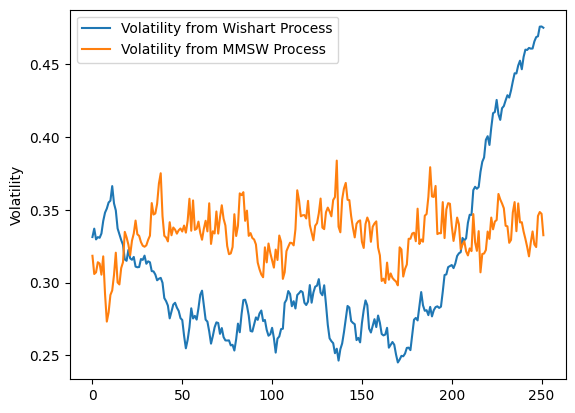

In [14]:
# Volatility Simulation and Covariance
Simulation= pd.DataFrame()
Simulation["Volatility from Wishart Process"]=  np.sqrt(Sigma_WP[: , 5, 1, 1])
#Simulation["Volatility from Wishart Process"]=  np.sqrt(Sigma_WP[: , 1, 1, 1])
#Simulation["Volatility from Shifted W. Process"]=  np.sqrt(Sigma_SW[:, 5, 1, 1])
#Simulation["Volatility from Shifted W. Process"]=  np.sqrt(Sigma_SW[:, 1, 1, 1])
Simulation["Volatility from MMSW Process"]= np.sqrt(Sigma_MMSW[:,  5, 1, 1])
#Simulation["Volatility from MMSW Process"]= np.sqrt(Sigma_MMSW[:, 1, 1, 1])
Simulation.plot()
plt.ylabel("Volatility")


Text(0, 0.5, 'Correlation')

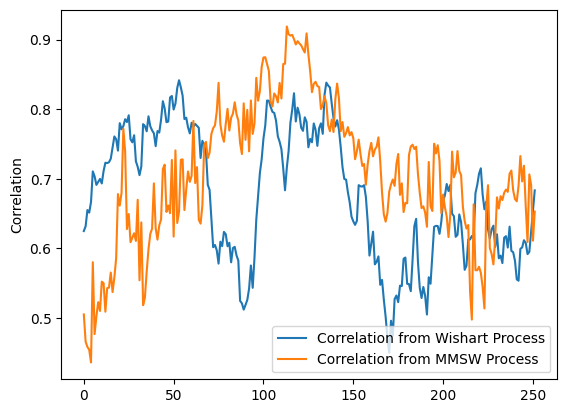

In [15]:
# Correlation Simulation 
Simulation= pd.DataFrame()
Simulation["Correlation from Wishart Process"]=  Sigma_WP[: , 0, 0, 1]/ np.sqrt(Sigma_WP[: , 0, 1, 1]* Sigma_WP[: , 0, 0, 0])
#Simulation["Volatility from Wishart Process"]=  np.sqrt(Sigma_WP[: , 1, 1, 1])
#Simulation["Correlation from Shifted W. Process"]=  Sigma_SW[: , 0, 0, 1]/ np.sqrt(Sigma_SW[: , 0, 1, 1]* Sigma_SW[: , 0, 0, 0])
#Simulation["Volatility from Shifted W. Process"]=  np.sqrt(Sigma_SW[:, 1, 1, 1])
Simulation["Correlation from MMSW Process"]= Sigma_MMSW[: , 0, 0, 1]/ np.sqrt(Sigma_MMSW[: , 0, 1, 1]* Sigma_MMSW[: , 0, 0, 0])
#Simulation["Volatility from MMSW Process"]= np.sqrt(Sigma_MMSW[:, 1, 1, 1])
Simulation.plot()
plt.ylabel("Correlation")

# Parameters Estimation

In [ ]:
# Change parameters formats for reason of integration and optimization
def set_omega(omega_1, omega_2):
    return np.array([omega_1, omega_2])
def set_theta(theta):
    M= np.array([[theta[0], theta[1]], [theta[2], theta[3]]])
    Q= np.array([[theta[4], theta[5]], [theta[6], theta[7]]])
    rho= np.array([theta[8], theta[9]])
    beta= theta[10]
    return M, Q, rho, beta

def h(omega, theta, t):
    M, Q, rho, beta= set_theta(theta)
    try:
        y_tplustau= np.log(np.array([first[tau*252 +t], second[tau*252 + t]]))
        y_t= np.log(np.array([first[t], second[t]]))
        result= np.exp(1j * np.dot(omega, np.subtract(y_tplustau, y_t))) - Phi_W(tau, omega, np.subtract(y_tplustau, y_t), M, Q, rho, beta)
    except:
        result= 0
    return result

def h_hat(omega, theta):
    result= 0
    for t in range (T_):
        result+= h(omega, theta, t)
    return 1 / T_ * result

def h_hat_norm (theta):
    def h_hat_norm_omega(omega_1, omega_2):
        omega= np.array([omega_1, omega_2])
        return np.linalg.norm(h_hat(omega, theta)) ** 2
    result= integral_func(h_hat_norm_omega, omega_lb,omega_ub,omega_lb,omega_ub)
    return result

def Uh(omega, t, theta_hat_1):
    def phi_(x):
        return 1- x 
    B_T= - (T_+1)/6
    result= phi_(0) * np.conjugate(h(omega, theta_hat_1, t))
    for j in range (1,T_+1):
        s= ((T_-1/2) + j)/B_T
        result+= phi_(s)* (np.conjugate(h(omega, theta_hat_1, t - j)) + np.conjugate(h(omega, theta_hat_1, t + j)))
    return result

def nu(theta, t):
    def prod (omega_1, omega_2):
        omega= set_omega(omega_1, omega_2)
        return Uh(omega, t, theta_hat_1) * h_hat(omega, theta)
    result = integral_func(prod, omega_lb, omega_ub, omega_lb, omega_ub)
    return result

def omeg(theta, t):
    def prod (omega_1, omega_2):
        omega= set_omega(omega_1, omega_2)
        return h(omega, theta_hat_1, t) * np.conjugate(h_hat(omega, theta))
    result= integral_func(prod, omega_lb, omega_ub, omega_lb, omega_ub)
    return result

def C(t,l):
    def prod (omega_1, omega_2):
        omega= set_omega(omega_1, omega_2)
        return Uh(omega, t, theta_hat_1) * h(omega, theta_hat_1, l)
    return integral_func(prod, omega_lb, omega_ub, omega_lb, omega_ub)/ (T_ - len(theta_hat_1))

def target_for_theta(theta):
    C_= [list(list(C(t,l) for l in range(1,T_)) for t in range(1,T_))]
    def intermediate_(C_):
        alpha= 0.02
        while np.linalg.det(alpha * np.ones(T_-1) + np.matmul(C_,C_)) == 0:
            alpha+= 0.01 
        return np.linalg.inv(alpha * np.ones(T_-1) + np.matmul(C_,C_))
    intermediate= intermediate_(C_)
    omega_bar= list(np.conjugate(omeg(theta, t)) for t in range(1,T_))
    nu_bar= list(np.conjugate(nu(theta, t)) for t in range(1,T_))
    result= np.dot(np.matmul(np.transpose(omega_bar), intermediate), nu_bar)
    return result
def save_output(setting_, theta):
    output= pd.read_csv("data/output.csv")
    output[setting_]= pd.Series(theta)
    output.to_csv("data/output.csv", sep=",", encoding= "utf-8", index= False)
    return

In [ ]:
#theta_hat_1= np.zeros(11)
# Adding linear constraint for correlations rho1 and rho2 to be between 0 and 1.
df= pd.DataFrame()
df.to_csv("data/output.csv", sep=",", encoding= "utf-8")
A= np.array([[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]])
rho_lb= np.array([-1, -1, 1.5])
rho_ub= np.array([1, 1, np.inf])
cons= scipy.optimize.LinearConstraint(A,rho_lb, rho_ub)




# Setting parameters for S&P and DAX for the whole period
first, second, y_0= first_second("SPvsDAX", -1)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_SPDAX_regime=-1", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)
save_output("theta_0_SPDAX_regime=-1", theta_0)          




# Setting parameters for S&P and DAX for period 0
first, second, y_0= first_second("SPvsDAX", 0)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_SPDAX_regime=0", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)["x"]
save_output("theta_0_SPDAX_regime=0", theta_0)



# Setting parameters for S&P and DAX for period 1
first, second, y_0= first_second("SPvsDAX", 1)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_SPDAX_regime=1", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)["x"]
save_output("theta_0_SPDAX_regime=1", theta_0)



# Setting parameters for RBC vs BMO for whole period
first, second, y_0= first_second("RBCvsBMO", -1)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_RBCBMO_regime=-1", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)["x"]
save_output("theta_0_RBCBMO_regime=-1", theta_0)



# Setting parameters for RBC vs BMO for period 0
first, second, y_0= first_second("RBCvsBMO", 0)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_RBCBMO_regime=0", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)["x"]
save_output("theta_0_RBCBMO_regime=0", theta_0)



# Setting parameters for RBC vs BMO for period 1
first, second, y_0= first_second("RBCvsBMO", 1)

# finding the optimal value for theta_hat_1 that will be used as an initial value for finding the optimal theta_o
theta_hat_1= scipy.optimize.minimize(h_hat_norm, theta_init, constraints=cons)["x"]
save_output("theta_hat_RBCBMO_regime=1", theta_hat_1)

# finding the optimal value for theta_0 starting from theta_hat_1
theta_0= scipy.optimize.minimize(target_for_theta, theta_hat_1, constraints=cons)["x"]
save_output("theta_0_RBCBMO_regime=1", theta_0)



In [41]:
# SP500 vs APPLE
#data_1= pd.read_csv("Surfaces/Surfaces_March_2025/New_SPvsAPPLE_Wishart_Surface.csv")
#data_2= pd.read_csv("Surfaces/Surfaces_March_2025/SPvsAPPLE_MMS_Wishart_Surface.csv")
#data_2= pd.read_csv("Surfaces/Surfaces_March_2025/SPvsAPPLE_Shifted_Wishart_Surface.csv")
#data_1= pd.read_csv("Surfaces/SPvsAPPLE_MMS_Wishart_Surface.csv")

# GOOGLE vs INTEL
#data_1= pd.read_csv("Surfaces/Surfaces_March_2025/GOOGvsINTC_Wishart_Surface_tild.csv")
data_2= pd.read_csv("Surfaces/Surfaces_March_2025/GOOGvsINTC_MMS_Wishart_Surface_tild.csv")
data_1= pd.read_csv("Surfaces/Surfaces_March_2025/GOOGvsINTC_Shifted_Wishart_Surface_tild.csv")
#data_2= pd.read_csv("Surfaces/NVIDIAvsINTEL_Wishart_Surface.csv")
#data_1= pd.read_csv("Surfaces/NVIDIAvsINTEL_Shifted_Wishart_Surface.csv")
#data_1= pd.read_csv("Surfaces/NVIDIAvsINTEL_MMS_Wishart_Surface.csv")


In [32]:
data= data_2

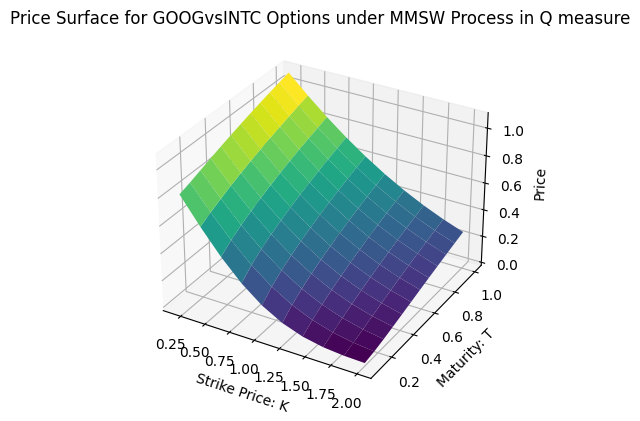

In [34]:
# generating PRice Surfaces
x= data["K"].values
y= data["T"].values
z= data["Price"].values

# Assuming x1 and x2 represent a grid-like variation
X1= np.reshape(x,(10,12))
X2= np.reshape(y,(10,12))
Z= np.reshape(z,(10,12))
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the data points in 3D
#ax.scatter(X1, X2, Z, c='b', marker='.')  # Blue color, circle marker

# Plot the surface using reshaped data and 'viridis' colormap
surf = ax.plot_surface(X1, X2, Z, cmap='viridis')


# Add labels and title
ax.set_xlabel('Strike Price: K')
ax.set_ylabel('Maturity: T')
ax.set_zlabel('Price')
ax.set_title('Price Surface for GOOGvsINTC Options under MMSW Process in Q measure')
#plt.colorbar(surf, shrink=0.5, aspect=5)  # Add colorbar

# Set axis limits (optional)
# ax.set_xlim(min(x), max(x))
# ax.set_ylim(min(y), max(y))
# ax.set_zlim(min(z), max(z))

plt.show()

In [42]:
data_1= data_1[data_1["K"] < 2]
data_1= data_1[data_1["T"] > 4/12]
data_2= data_2[data_2["K"] < 2]
data_2= data_2[data_2["T"] > 4/12]

In [11]:
data_1.to_csv("test_data_1.csv")

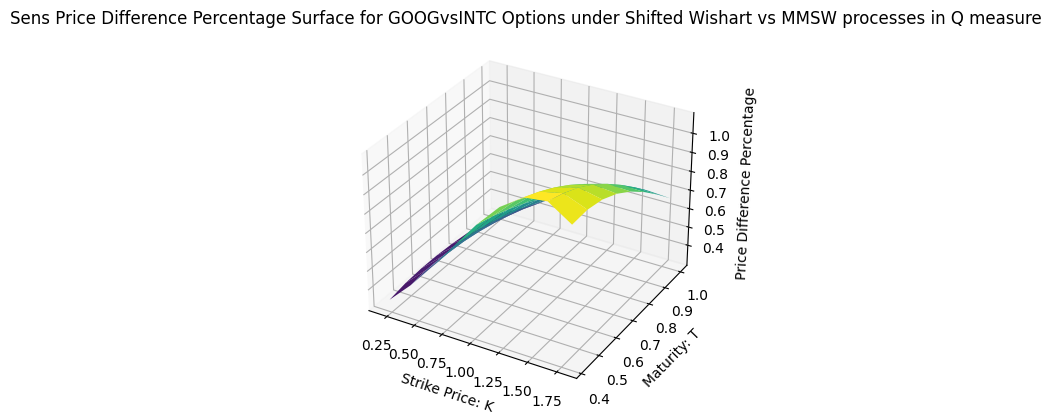

In [43]:
# generating comparison surfaces
x= data_1["K"].values
y= data_1["T"].values
data_3= pd.DataFrame()
data_3["Price"]= (100 * (data_2["Price"]/data_1["Price"] - 1 ))
#data_3['Price']= data_2["Price"] - data_1["Price"]
z= data_3["Price"].values

#X1= np.reshape(x,(10,12))
#X2= np.reshape(y,(10,12))
#Z= np.reshape(z,(10,12))
X1= np.reshape(x,(9,8))
X2= np.reshape(y,(9,8))
Z= np.reshape(z,(9,8))

# Assuming x1 and x2 represent a grid-like variation
#X1, X2= np.meshgrid(x, y)  # Creates a 2D grid of x1 and x2 values

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the data points in 3D
#ax.scatter(x, y, z, c='b', marker='.')  # Blue color, circle marker

# Plot the surface using the reshaped data
ax.plot_surface(X1, X2, Z, cmap='viridis')  # Use a colormap for visualization


# Add labels and title
ax.set_xlabel('Strike Price: K')
ax.set_ylabel('Maturity: T')
#ax.set_zlabel('Price Difference')
ax.set_zlabel('Price Difference Percentage')
title= "Sens Price Difference Percentage Surface for GOOGvsINTC Options under Shifted Wishart vs MMSW processes in Q measure"
ax.set_title(title)

# Set axis limits (optional)
# ax.set_xlim(min(x), max(x))
# ax.set_ylim(min(y), max(y))
# ax.set_zlim(min(z), max(z))

plt.show()

#plt.savefig(title+".png")

In [29]:
# Computing Historical Covariance
#data= pd.read_csv("/Users/behzad/Dropbox/Phd at Sharif/Wishart Process/MMSW Process/Wishart Process Implementation/data/data_March_28/NVDIAvsINTL/data_0_N_I.csv")[["NVDA", "INTC"]]
#data= pd.read_csv("/Users/behzad/Dropbox/Phd at Sharif/Wishart Process/MMSW Process/Wishart Process Implementation/data/data_March_28/S&PvsAPPL/data_0.csv")[["S&P", "AAPL"]]
data= pd.read_csv("data/data_March_28/GOOGvsINTC/data_0.csv")[["GOOG", "INTC"]]


In [9]:
SP_ret= np.log(1+data["S&P"].pct_change()).dropna()
AAPL_ret= np.log(1+data["AAPL"].pct_change()).dropna()
print("SP mean return: ", 250* SP_ret.mean())
print("AAPL mean return: ", 250* AAPL_ret.mean())
#cov_matrix = 252 * np.cov(SP_ret, AAPL_ret)
cov_matrix = 252 * np.cov(SP_ret, AAPL_ret)

SP mean return:  0.10309710021550934
AAPL mean return:  0.4064566245709363


In [11]:
NVDA_ret= np.log(1+data["NVDA"].pct_change()).dropna()
INTC_ret= np.log(1+data["INTC"].pct_change()).dropna()
print("NVDA mean return: ", 250* NVDA_ret.mean())
print("INTC mean return: ", 250* INTC_ret.mean())
#cov_matrix = 252 * np.cov(SP_ret, AAPL_ret)
cov_matrix = 252 * np.cov(NVDA_ret, INTC_ret)


NVDA mean return:  0.45672853538873176
INTC mean return:  0.05986412814772689


In [6]:
data= pd.read_csv("data/data_March_28/S&PvsAPPL_2014/data_S_A_0_2014.csv")

In [11]:
GOOG_ret= np.log(1+data["GOOG"].pct_change()).dropna()
INTC_ret= np.log(1+data["INTC"].pct_change()).dropna()
print("GOOG mean return: ", 250* GOOG_ret.mean())
print("INTC mean return: ", 250* INTC_ret.mean())
#cov_matrix = 252 * np.cov(SP_ret, AAPL_ret)
cov_matrix = 252 * np.cov(GOOG_ret, INTC_ret)
print("Cov matrix: ", cov_matrix)

GOOG mean return:  0.22525320413400243
INTC mean return:  0.07519096480800767
Cov matrix:  [[0.10406738 0.03920364]
 [0.03920364 0.0874889 ]]


In [7]:
GOOG_ret= np.log(1+data["S&P 500 in USD"].pct_change()).dropna()
INTC_ret= np.log(1+data["AAPL"].pct_change()).dropna()
print("SP mean return: ", 250* GOOG_ret.mean())
print("AAPL mean return: ", 250* INTC_ret.mean())
#cov_matrix = 252 * np.cov(SP_ret, AAPL_ret)
cov_matrix = 252 * np.cov(GOOG_ret, INTC_ret)
print("Cov matrix: ", cov_matrix)

SP mean return:  0.06474146950232884
AAPL mean return:  0.4225645519911811
Cov matrix:  [[0.0366402  0.0403942 ]
 [0.0403942  0.13315747]]


In [73]:
print(cov_matrix)
corr= cov_matrix[0][1]/ np.sqrt(cov_matrix[0][0] * cov_matrix[1][1])
print("Correlation: ", corr)

[[0.1080171  0.03296524]
 [0.03296524 0.0843266 ]]
Correlation:  0.34540426726247886


In [10]:
from statsmodels.tsa.stattools import adfuller

#AAPL_rolling= AAPL_ret.rolling(window=100).var().dropna()
AAPL_rolling= AAPL_ret.rolling(window=100).std().dropna()
# Perform ADF test
result = adfuller(AAPL_rolling)
result

(-3.9674148451908033,
 0.0015910841806459073,
 30,
 4844,
 {'1%': -3.431700695438312,
  '5%': -2.862136857096911,
  '10%': -2.567087708483206},
 -63924.47943560347)

# Confidence Interval for \lambda_0 & \lambda_1

In [2]:
import io
import sys
from contextlib import redirect_stdout

In [9]:
#data= pd.read_csv("/Users/behzad/Dropbox/Phd at Sharif/Wishart Process/MMSW Process/Wishart Process Implementation/data/data_March_28/S&PvsAPPL/data_.csv")["S&P 500 in USD"]
#data= pd.read_csv("/Users/behzad/Dropbox/Phd at Sharif/Wishart Process/MMSW Process/Wishart Process Implementation/data/data_March_28/NVDIAvsINTL/data_N_I.csv")["NVDA"]
data= pd.read_csv("data/data_March_28/S&PvsBond2014/data_S_I_2014.csv")["S&P"]
data["returns"]= np.log(data/data.shift(1))
data["std"]= data["returns"].rolling(window=20).std().dropna()
X= data["std"].to_numpy().reshape(-1, 1)

def exp_func(lambd, tranmat):
    lambda_0, lambda_1= lambd[0], lambd[1]
    t= 1/252
    p_11 = lambda_1 /(lambda_0 + lambda_1) + lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_12= lambda_0 /(lambda_0 + lambda_1) - lambda_0 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_21= lambda_1 /(lambda_0 + lambda_1) - lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    p_22= lambda_0 /(lambda_0 + lambda_1) + lambda_1 / (lambda_0 + lambda_1) * np.exp(- t * (lambda_0 + lambda_1))
    exp_value= np.array([[p_11, p_12], [p_21, p_22]])
    return np.linalg.norm(exp_value - tranmat)

lambda_array=pd.DataFrame(columns=["lambda_0", "lambda_1"])

for i in range(1000):  
        model = hmm.GaussianHMM(n_components=2, covariance_type="full", n_iter=1000)
        model.fit(X)
        tranmat= model.transmat_ 
        lambda_init= np.array([0.1,0.1])
        [lambda_0, lambda_1]= scipy.optimize.minimize(exp_func, lambda_init, tranmat)["x"]
        lambda_0, lambda_1 = min([lambda_0, lambda_1]), max([lambda_0, lambda_1])
        new_lambda={"lambda_0": lambda_0, "lambda_1": lambda_1} 
        if lambda_0 <250 and lambda_1<250: # removing outliers
            lambda_array= pd.concat([lambda_array, pd.DataFrame([new_lambda])], ignore_index=True) 
            

#lambda_array.to_csv("/Users/behzad/Dropbox/Phd at Sharif/Wishart Process/MMSW Process/Wishart Process Implementation/data/data_March_28/S&PvsAPPL/lambda_array.csv")
#lambda_array.to_csv("data/data_March_28/GOOGvsINTC/lambda_array.csv")
lambda_0_std=lambda_array["lambda_0"].std()
lambda_1_std=lambda_array["lambda_1"].std()
print("lambda_0 standard deviation: ", lambda_0_std)
print("lambda_1 standard deviation: ", lambda_1_std)

/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_11405/273170301.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  lambda_array= pd.concat([lambda_array, pd.DataFrame([new_lambda])], ignore_index=True)
Model is not converging.  Current: 9393.293064454507 is not greater than 9393.297728932215. Delta is -0.0046644777085020905
Model is not converging.  Current: 9393.304525631436 is not greater than 9393.314668729709. Delta is -0.010143098272237694
Model is not converging.  Current: 9393.53178646052 is not greater than 9393.63905073653. Delta is -0.10726427601002797
Model is not converging.  Current: 11563.998198901852 is not greater than 11571.763778875378. Delta is -7.765579973525746
Model is not converging.  Current: 11566.76398

lambda_0 standard deviation:  0.00098300044940805
lambda_1 standard deviation:  0.00615072283151724


In [4]:
# Regime Detection vs VIX visualization 
sp_ief= pd.read_csv("data/data_March_28/S&PvsBond/SP_IEF_turb_reg.csv")
vix= pd.read_csv("data/vix_daily.csv")


In [6]:
vix

,Price,Adj Close,Close,High,Low,Open,Volume
0,Ticker,^VIX,^VIX,^VIX,^VIX,^VIX,^VIX
1,Date,NaN,NaN,NaN,NaN,NaN,NaN
2,1990-01-02,17.239999771118164,17.239999771118164,17.239999771118164,17.239999771118164,17.239999771118164,0
3,1990-01-03,18.190000534057617,18.190000534057617,18.190000534057617,18.190000534057617,18.190000534057617,0
4,1990-01-04,19.219999313354492,19.219999313354492,19.219999313354492,19.219999313354492,19.219999313354492,0
...,...,...,...,...,...,...,...
9001,2025-09-25,16.739999771118164,16.739999771118164,17.739999771118164,16.31999969482422,16.549999237060547,0
9002,2025-09-26,15.289999961853027,15.289999961853027,17.049999237060547,15.289999961853027,16.889999389648438,0
9003,2025-09-29,16.1200008392334,16.1200008392334,16.290000915527344,15.739999771118164,15.84000015258789,0
9004,2025-09-30,16.280000686645508,16.280000686645508,16.700000762939453,16.020000457763672,16.489999771118164,0


/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_5487/4090739823.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  vix = pd.read_csv("data/vix_daily.csv", parse_dates=["Date"]).set_index("Date")


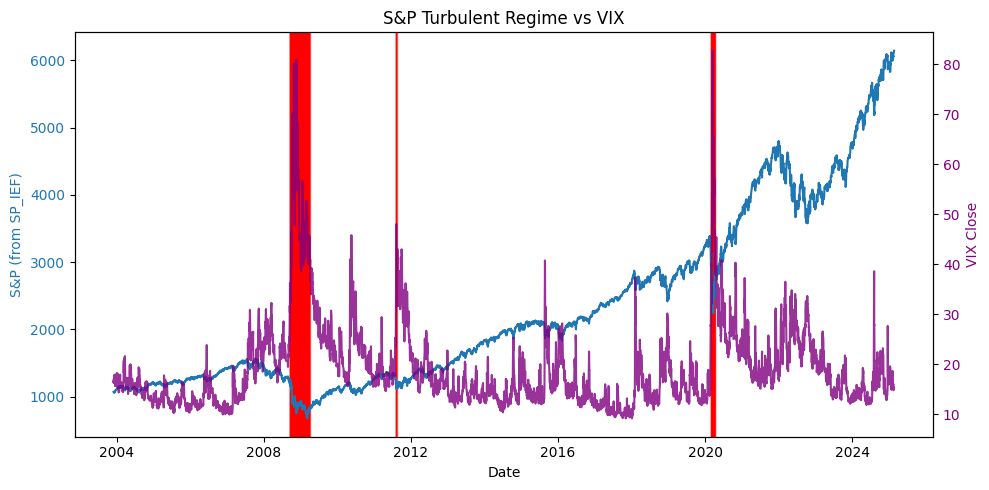

In [157]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data (adjust paths if needed)
sp_ief = pd.read_csv("data/data_SP_AAPL_backtest.csv", parse_dates=["Date"]).set_index("Date")
vix = pd.read_csv("data/vix_daily.csv", parse_dates=["Date"]).set_index("Date")

# Select series
sp_series = sp_ief["A1"].rename("S&P")
vix_series = vix["Close"].rename("VIX Close")

# Align on dates
df = pd.concat([sp_series, vix_series], axis=1).dropna()

# Prepare turbulence dates (must align to df index)
turb_mask = (sp_ief["Regime_vol_ret"] == 1)
turb_dates = sp_ief.index[turb_mask]
turb_dates = turb_dates.intersection(df.index)  # ensure they exist in the plot range

# Plot with twin y-axes
fig, ax1 = plt.subplots(figsize=(10, 5))
color1 = "tab:blue"
ax1.set_xlabel("Date")
ax1.set_ylabel("S&P (from SP_IEF)", color=color1)
ax1.plot(df.index, df["S&P"], color=color1, label="S&P", zorder=2)
ax1.tick_params(axis="y", labelcolor=color1)


ax2 = ax1.twinx()
color2 = "purple"  # was "tab:red"
ax2.set_ylabel("VIX Close", color=color2)
ax2.plot(df.index, df["VIX Close"], color=color2, label="VIX Close", alpha=0.8, zorder=2)
ax2.tick_params(axis="y", labelcolor=color2)

# Vertical red lines on turbulence dates
for d in turb_dates:
    ax1.axvline(d, color="red", linestyle="-", linewidth=1, alpha=0.5, zorder=1)

plt.title("S&P Turbulent Regime vs VIX")
fig.tight_layout()
plt.show()

In [12]:
sp_ief


,Unnamed: 0.1,Unnamed: 0,S&P,IEF,SPret,SP_ret_std,Regime_SP_ret_std,Regime_vol_ret,SP_Turbulent_index_ret
Date,,,,,,,,,
2003-12-01,0,0,1070.119995,46.042713,NaN,NaN,NaN,NaN,NaN
2003-12-02,1,1,1066.619995,46.174858,-0.003276,NaN,NaN,NaN,NaN
2003-12-03,2,2,1064.729980,46.053730,-0.001774,NaN,NaN,NaN,NaN
2003-12-04,3,3,1069.719971,46.152824,0.004676,NaN,NaN,NaN,NaN
2003-12-05,4,4,1061.500000,46.714622,-0.007714,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2014-12-19,2716,2716,2070.649902,84.599159,0.004560,0.009917,0.0,NaN,NaN
2014-12-22,2717,2717,2078.540039,84.599159,0.003803,0.009886,0.0,NaN,NaN
2014-12-23,2718,2718,2082.169922,83.898232,0.001745,0.009875,0.0,NaN,NaN


# Backtest

In [ ]:
# Preparing data for SP-IEF
data= pd.read_csv("data/data.csv") # SP vs Bond
IEF= pd.read_csv("data/IEF.csv")
# Ensure Date columns are parsed as datetime for both dataframes
data["Date"] = pd.to_datetime(data["Date"], errors='coerce')
IEF["Date"] = pd.to_datetime(IEF["Date"], errors='coerce')

# Merge on Date, keeping only required columns
data = pd.merge(
    data[["Date", "S&P 500 in USD"]],
    IEF[["Date", "IEF"]],
    on="Date",
    how="inner"
)
data.to_csv("data/data_SP_IEF.csv")

/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_5487/1341127507.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  IEF["Date"] = pd.to_datetime(IEF["Date"], errors='coerce')


In [66]:
#data= pd.read_csv("data/data.csv") # SP vs AAPL
#data=data[["Date", "S&P 500 in USD", "AAPL"]] # SP vs AAPL
#data = data.rename(columns={'S&P 500 in USD': 'A1', 'AAPL': 'A2'}) # SP vs AAPL

#data= pd.read_csv("data/GOOG_INTC.csv") # GOOG vs INTC
#data=data[["Date", "GOOG", "INTC"]] # GOOG vs INTC
#data = data.rename(columns={'GOOG': 'A1', 'INTC': 'A2'}) # GOOG vs INTC

data= pd.read_csv("data/data_March_28/S&PvsAPPL/data_2014_2024.csv") # SP vs Bond
data= data[["Date", "S&P 500 in USD", "AAPL"]]
data = data.rename(columns={'S&P 500 in USD': 'A1', 'AAPL': 'A2'}) # SP vs Bond

data["A1_returns"]= np.log(data["A1"]/data["A1"].shift(1))
data["A2_returns"]= np.log(data["A2"]/data["A2"].shift(1))
data["A1_vol"]= data["A1_returns"].rolling(window=20).std().dropna()
data["A2_vol"]= data["A2_returns"].rolling(window=20).std().dropna()
# Regime detection for SP volatility
reg_pred_=np.empty(20)
reg_pred_[:]=np.nan
model= hmm.GaussianHMM(n_components=2, covariance_type="full", n_iter=1000)
X= data[["A1_vol"]].to_numpy()[20:]
model.fit(X)
reg_pred= model.predict(X)
reg_pred=np.concatenate((reg_pred_,reg_pred), axis= 0)
if find_majority(reg_pred)[0]==1:
    reg_pred= 1- reg_pred
data["Regime_A1_vol"]= reg_pred
regim=1 - find_majority(reg_pred)[0]
regime_rows= data["Regime_A1_vol"].isin([regim])
data_regime= data[regime_rows]
X=data_regime[["A1_returns"]].to_numpy()
model.fit(X)
reg_pred_0= model.predict(X)
if find_majority(reg_pred_0)[0]==1:
    reg_pred_0= 1- reg_pred_0
reg_pred_1=np.empty(len(data))
reg_pred_1[:]=np.nan
data["Regime_vol_ret"]= reg_pred_1
data.loc[regime_rows, "Regime_vol_ret"]= reg_pred_0
# data.to_csv("data/data_SP_AAPL_vol_ret_regime.csv") # SP vs AAPL
#data.to_csv("data/data_GOOG_INTC_vol_ret_regime.csv") # GOOG vs INTC

Even though the 'startprob_' attribute is set, it will be overwritten during initialization because 'init_params' contains 's'
Even though the 'transmat_' attribute is set, it will be overwritten during initialization because 'init_params' contains 't'
Even though the 'means_' attribute is set, it will be overwritten during initialization because 'init_params' contains 'm'
Even though the 'covars_' attribute is set, it will be overwritten during initialization because 'init_params' contains 'c'
Model is not converging.  Current: 1227.0421730001062 is not greater than 1227.0766499492445. Delta is -0.034476949138252166


In [ ]:
# Estimated Parameters for S&P and Appl on Normal Period 2004-2024

M_N= np.array([[-1.0202, 0.1418], [1.3596, -0.8224]]) # estimation Fb 14
Q_N= np.array([[0.0689, 0], [0, 0.1173]]) # estimation Fb 14
beta_N= 7.5504 # estimation Fb 14
rho_bar_N= np.array([-0.5499, -0.1930]) # estimation Fb 14
mu_N= np.array([0.1031, 0.4065]) # estimation Fb 14
Sigma_inf_normal_N= np.array([[0.0208, 0.0232], [0.0232, 0.1014]]) # estimation Fb 14
Sigma_inf_total_N= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
Sigma_inf_hist_N= np.array([[0.02096, 0.0233], [0.0233, 0.1022]])
Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)
sighat_N= Sig_hat_total_vs_normal_N
# risk free rate
r=0.04

lambda_bar_0= 1.0657
#lambda_0= 0.0001
lambda_bar_1= 3.76497
#lambda_01 and lambda_10
daily_transmat= np.array([[0.99581131, 0.00418869],
       [0.01479807, 0.98520193]])


p=lambda_bar_1 / (lambda_bar_0 + lambda_bar_1)


Lambda= np.array([[1, 0],
       [0, 1]])
M_tild_N= M_N - Q_N @ Lambda

rho_bar_N= np.matrix.transpose(np.asmatrix(rho_bar_N))
M_N= np.asmatrix(M_N)
Q_N= np.asmatrix(Q_N)
M_tild_N= np.asmatrix(M_tild_N)


#Estimated Wishart for Total Data for SP500 vs APPLE

M_T= np.array([[-1.0027, 0.2022], [1.5593, -0.9996]]) # Feb 12 coef= 10 &  Feb 13 coef= 10
Q_T= np.array([[0.0769, 0], [0, 0.0992]]) ## Feb 12 coef= 10 &  Feb 13 coef= 10

beta_T=9.7316 # Feb 12 coef= 10 &  Feb 13 coef= 10
rho_bar_T= np.array([-0.5055, -0.2170]) # Feb 12 coef= 10 &  Feb 13 coef= 10

mu_T= np.array([0.0799, 0.3151]) #Feb 11, Feb 12 coef=10 &  Feb 13 coef= 10

Sigma_inf_normal_T= np.array([[0.03669, 0.03966], [0.03966, 0.10977]]) # Feb 12 coef= 10 &  Feb 13 coef= 10
Sigma_inf_total_T= np.array([[0.0370, 0.0400], [0.0400, 0.1107]])
Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)
#Matrix sigma^hat
sighat_T= Sig_hat_total_vs_normal_T
# risk free rate
r=0.04

M_tild_T= M_T - Q_T @ Lambda

rho_bar_T= np.matrix.transpose(np.asmatrix(rho_bar_T))
M_T= np.asmatrix(M_T)
Q_T= np.asmatrix(Q_T)
M_tild_T= np.asmatrix(M_tild_T)

In [67]:
# Estimated Parameters for S&P and Appl on Normal Period 2004-2014


M_N= np.array([[-0.9694, 0.1660], [1.5315, -0.9669]]) # estimation Fb 14

Q_N= np.array([[0.0779, 0], [0, 0.1187]]) # estimation Fb 14

beta_N= 9.4217 # estimation Fb 14

y_0= np.array([6.9755,-1.1188])
#y_0_0= np.array([0,0])
#y_0_0= np.log(np.array([5, 4]))


rho_bar_N= np.array([-0.5074, -0.2167]) # estimation Fb 14

mu_N= np.array([0.0647, 0.4226]) # estimation Fb 14
#mu= np.array([r, r])



Sigma_inf_normal_N= np.array([[0.0363, 0.0401], [0.0401, 0.1321]]) # estimation Fb 14

Sigma_inf_total_T= np.array([[0.0398 , 0.0396], [0.0396, 0.1314]]) # to be erased

#Sigma_inf_total_N= np.array([[0.0398, 0.0396], [0.0396, 0.1315]])
Sigma_inf_total_N= np.array([[0.0366,  0.0404], [0.04039,  0.1331]]) #What is the difference between Sigma_inf_total_N and Sigma_inf_hist_N
Sigma_inf_hist_N= np.array([[0.0366,  0.0404], [0.04039,  0.1331]])
#Sigma_inf_total_N=np.array([[0.00143, 0], [0, 0.00192]]) # Some value just to test
#Sigma_inf_crisis= np.array([[0.0305, 0.0372], [0.0372, 0.0594]])
Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)
#Sig_hat_crisis_vs_normal= np.subtract(Sigma_inf_crisis, Sigma_inf_normal)
#Matrix sigma^hat
sighat_N= Sig_hat_total_vs_normal_N

# risk free rate
r=0.04


lambda_bar_0= 10.94
#lambda_0= 0.0001
lambda_bar_1= 4.82
#lambda_01 and lambda_10

#daily_transmat= np.array([[0.99581131, 0.00418869],[0.01479807, 0.98520193]])


p=lambda_bar_1 / (lambda_bar_0 + lambda_bar_1)


Lambda= np.array([[1, 0],
       [0, 1]])
M_tild_N= M_N - Q_N @ Lambda

rho_bar_N= np.matrix.transpose(np.asmatrix(rho_bar_N))
M_N= np.asmatrix(M_N)
Q_N= np.asmatrix(Q_N)
M_tild_N= np.asmatrix(M_tild_N)

#Estimated Wishart for Total Data for SP500 vs APPLE 2004-2014
M_T= np.array([[-0.9956, 0.1618], [1.4483, -0.9976]]) # Feb 12 coef= 10 &  Feb 13 coef= 10

Q_T= np.array([[0.0820, 0], [0, 0.1221]]) ## Feb 12 coef= 10 &  Feb 13 coef= 10

beta_T=9.8168 # Feb 12 coef= 10 &  Feb 13 coef= 10

rho_bar_T= np.array([-0.5071, -0.2168]) # Feb 12 coef= 10 &  Feb 13 coef= 10

mu_T= np.array([0.0583, 0.4035]) #Feb 11, Feb 12 coef=10 &  Feb 13 coef= 10


Sigma_inf_normal_T= np.array([[0.0395, 0.0396], [0.0396, 0.1304]]) # Feb 12 coef= 10 &  Feb 13 coef= 10
Sigma_inf_total_T= np.array([[0.0398 , 0.0396], [0.0396, 0.1314]])

Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)

sighat_T= Sig_hat_total_vs_normal_T

M_tild_T= M_T - Q_T @ Lambda
# Monte Carlo Parameters

rho_bar_T= np.matrix.transpose(np.asmatrix(rho_bar_T))
M_T= np.asmatrix(M_T)
Q_T= np.asmatrix(Q_T)
M_tild_T= np.asmatrix(M_tild_T)

In [122]:
# Parameters for GOOG vs INTEL on normal period 2004-2024

M_N= np.array([[-1, 0.839], [1.722, -1]]) # Est Feb 22
Q_N= np.array([[0.152, 0], [0, 0.092]]) # Est Feb 22
beta_N= 9.935 # Initial Point Feb 22
#y_0= np.array([0.9124,2.5416]) # Est Feb 22
rho_bar_N= np.array([-0.408, -0.1275]) # Est Feb 22
Sigma_inf_normal_N= np.array([[0.087, 0.0327], [0.0327, 0.099]]) # Est Feb 22
Sigma_inf_hist_N= np.array([[0.0877, 0.03346], [0.03346, 0.10026]])
Sigma_inf_total_N= np.array([[0.0927, 0.0424], [0.0424, 0.1107]])
Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)
sighat_N= Sig_hat_total_vs_normal_N

Lambda= np.array([[1, 0],
       [0, 1]])

lambda_bar_0= 44.003
lambda_bar_1= 128.685
mu_N= np.array([0.2439, 0.0814])

p=lambda_bar_1 / (lambda_bar_0 + lambda_bar_1)
M_tild_N= M_N - Q_N @ Lambda

rho_bar_N= np.matrix.transpose(np.asmatrix(rho_bar_N))
M_N= np.asmatrix(M_N)
Q_N= np.asmatrix(Q_N)
M_tild_N= np.asmatrix(M_tild_N)

# Estimated Wishart on Total Data for GOOG vs INTEL
M_T= np.array([[-0.999, -0.443], [1.444, -1]]) # Estimation Feb 22
Q_T= np.array([[0.149, 0], [0, 0.099]]) # Estimation Feb 22
beta_T= 9.911 # Initial point Feb 22
rho_bar_T= np.array([-0.386, -0.1876]) # Estimation Feb 22
Sigma_inf_normal_T= np.array([[0.092, 0.042], [0.042, 0.109]])  # Estimation Feb 22
Sigma_inf_total_T= np.array([[0.0927, 0.0424], [0.0424, 0.1107]])
Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)
sighat_T= Sig_hat_total_vs_normal_T

r=0.04

mu_T= np.array([0.209, 0.033])
M_tild_T= M_T - Q_T @ Lambda

rho_bar_T= np.matrix.transpose(np.asmatrix(rho_bar_T))
M_T= np.asmatrix(M_T)
Q_T= np.asmatrix(Q_T)
M_tild_T= np.asmatrix(M_tild_T)

In [ ]:
# Parameters for SP500 vs Bond on normal period 2004-2024

M_N= np.array([[-0.8908, -0.3075], [-0.1765, -0.9225]]) # Est Feb 22
Q_N= np.array([[0.0783, 0], [0, 0.0293]]) # Est Feb 22

beta_N= 8.1376  # Initial Point Feb 22
y_0= np.array([6.9755,3.8296]) # Est Feb 22
rho_bar_N= np.array([-0.4276, -0.2000]) # Est Feb 22
Sigma_inf_normal_N= np.array([[0.0292, -0.0036], [-0.0036, 0.0045]]) # Est Feb 22
Sigma_inf_hist_N= np.array([[0.0294, -0.0036], [-0.0036, 0.0045]]) # updated for SPvsBond
Sigma_inf_total_N= np.array([[0.037, -0.0041], [-0.0041, 0.00478]]) 

Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)
sighat_N= Sig_hat_total_vs_normal_N

r=0.025
Lambda= np.array([[1, 0],
       [0, 1]])

lambda_bar_0= 1.0657 # corrected
lambda_bar_1= 3.7650

mu_N= np.array([0.08336, 0.0349]) # updated for SPvsBond

p=lambda_bar_1 / (lambda_bar_0 + lambda_bar_1)
M_tild_N= M_N - Q_N @ Lambda

rho_bar_N= np.matrix.transpose(np.asmatrix(rho_bar_N))
M_N= np.asmatrix(M_N)
Q_N= np.asmatrix(Q_N)
M_tild_N= np.asmatrix(M_tild_N)

# Estimated Wishart on Total Data for SP500 vs Bon
M_T= np.array([[-0.9031, -0.3065], [-0.1711, -0.9963]]) # Estimation Feb 22
Q_T= np.array([[0.0845, 0], [0, 0.0300]]) # Estimation Feb 22
beta_T= 8.9308 # Initial point Feb 22
#y_0= np.array([0.9124,2.5416]) # Est Feb 22
rho_bar_T= np.array([-0.4638, -0.2136]) # Estimation Feb 22
Sigma_inf_normal_T= np.array([[0.0367, -0.0041], [-0.0041, 0.0047]])  # Estimation Feb 22
Sigma_inf_total_T= np.array([[0.037, -0.0041], [-0.0041, 0.00478]]) # updated for historical SP vs Bond
Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)
sighat_T= Sig_hat_total_vs_normal_T

mu_T= np.array([0.0799, 0.03347]) # updated for historical SP vs Bond

M_tild_T= M_T - Q_T @ Lambda

rho_bar_T= np.matrix.transpose(np.asmatrix(rho_bar_T))
M_T= np.asmatrix(M_T)
Q_T= np.asmatrix(Q_T)
M_tild_T= np.asmatrix(M_tild_T)

In [39]:
# Parameters for SP500 vs Bond on normal period 2004-2014

M_N= np.array([[-0.9509, -0.4962], [-0.2949, -0.9797]]) # Est Feb 22
Q_N= np.array([[0.0827, 0], [0, 0.0265]]) # Est Feb 22

beta_N= 9.1701  # Initial Point Feb 22
y_0= np.array([6.9755,3.8296]) # Est Feb 22

rho_bar_N= np.array([-0.4571, -0.2138]) # Est Feb 22

Sigma_inf_normal_N= np.array([[0.0366, -0.0070], [-0.0070, 0.0054]]) # Est Feb 22

Sigma_inf_total_T= np.array([[0.0396, -0.0056], [-0.0056, 0.00489]]) # to be erased

Sigma_inf_hist_N= np.array([[0.0369, -0.007], [-0.007, 0.0054]]) # unpdated for SP vs Bond
Sigma_inf_total_N= np.array([[0.0369, -0.007], [-0.007, 0.0048]])

Sig_hat_total_vs_normal_N= np.subtract(Sigma_inf_total_N, Sigma_inf_normal_N)

sighat_N= Sig_hat_total_vs_normal_N
sighat_N[1][1]=0 # We make the sighat positive definite

r=0.025
Lambda= np.array([[1, 0],
       [0, 1]])

lambda_bar_0= 0.6320 # corrected
lambda_bar_1= 2.6302

mu_N= np.array([0.06345, 0.0579]) # unpdated for SP vs Bond

p=lambda_bar_1 / (lambda_bar_0 + lambda_bar_1)
M_tild_N= M_N - Q_N @ Lambda

rho_bar_N= np.matrix.transpose(np.asmatrix(rho_bar_N))
M_N= np.asmatrix(M_N)
Q_N= np.asmatrix(Q_N)
M_tild_N= np.asmatrix(M_tild_N)


# Estimated Wishart on Total Data for SP vs Bond
M_T= np.array([[-1.0802, -0.4562], [-0.2561, -1.1091]]) # Estimation Feb 22
Q_T= np.array([[0.0895, 0], [0, 0.0281]]) # Estimation Feb 22

beta_T= 9.9722 # Initial point Feb 22

rho_bar_T= np.array([-0.4445, -0.2133]) # Estimation Feb 22

Sigma_inf_normal_T= np.array([[0.0393, -0.0056], [-0.0056, 0.0049]])  # Estimation Feb 22

Sigma_inf_total_T= np.array([[0.0396, -0.0056], [-0.0056, 0.00489]]) # updated for SPvsBond
Sig_hat_total_vs_normal_T= np.subtract(Sigma_inf_total_T, Sigma_inf_normal_T)

sighat_T= Sig_hat_total_vs_normal_T

mu_T= np.array([0.0610, 0.0557]) # updated for SPvsBond
M_tild_T= M_T - Q_T @ Lambda

rho_bar_T= np.matrix.transpose(np.asmatrix(rho_bar_T))
M_T= np.asmatrix(M_T)
Q_T= np.asmatrix(Q_T)
M_tild_T= np.asmatrix(M_tild_T)


In [68]:
# Portfolio Allocation Functions
# Constants and input matrices
delta = -5  # Risk aversion coefficient

def B_t (lambda_vector,M,Q,rho_bar,tau, delta):
  Gamma= M + delta /(1-delta) * np.matrix.transpose(Q) @ rho_bar @ np.matrix.transpose(lambda_vector)
  C= 0.5 * delta / (1-delta)**2 * lambda_vector @ lambda_vector.T
  Lambda= np.matrix.transpose(Q) @ ((1-delta)* np.eye(2) + delta * rho_bar @ np.matrix.transpose(rho_bar)) @ Q

  # Compute the block matrix F_ij(t) = exp( t * A ), where A is a 4x4 matrix composed of Gamma, Lambda, and C
  A = np.block([[Gamma, -2 * Lambda], [C, -Gamma.T]])

  F = expm(tau * A)

  # Extract F_11, F_12, F_21, F_22 from F
  F_11 = F[:2, :2]
  F_12 = F[:2, 2:]
  F_21 = F[2:, :2]
  F_22 = F[2:, 2:]

  # Compute B(t)
  return np.linalg.inv(F_22) @ F_21

# Myopic Portfolio
def portfolio_allocation_M(lambda_vector_M, delta):
  return (1 / (1 - delta)) * lambda_vector_M

# Wishart Portfolio after Buraschi
def portfolio_allocation_W(lambda_vector_W, M_W,Q_W,rho_bar_W,tau, delta):
  return (1 / (1 - delta)) * lambda_vector_W + 2 * B_t (lambda_vector_W, M_W,Q_W,rho_bar_W,tau, delta) @ Q_W.T @ rho_bar_W

# Theorem 1: Optimal Portfolio Strategy under Shifted Wishart Process
def portfolio_allocation_SW(lambda_vector_SW, M_SW,Q_SW,rho_bar_SW,Sigma_inf_SW,sighat_SW,tau, delta):
  inv_Sigma_SW = np.linalg.inv(Sigma_inf_SW)
  output= (1 / (1 - delta)) * lambda_vector_SW + 2 * B_t (lambda_vector_SW, M_SW,Q_SW,rho_bar_SW,tau, delta) @ Q_SW.T @ rho_bar_SW - 2 * inv_Sigma_SW @ sighat_SW @ B_t (lambda_vector_SW, M_SW,Q_SW,rho_bar_SW,tau, delta) @ Q_SW.T @ rho_bar_SW
  return output

# Theorem 2: Optimal Portfolio Strategy under MMSW Process
def portfolio_allocation_MMSW(lambda_vector_MW, M_MW, Q_MW, rho_bar_MW, Sigma_inf_MW,sighat_MW, state, tau, delta):
# Use the state-dependent widehat_Sigma_MC in the MMSW process
  widehat_Sigma_MC = sighat_MW if state == 1 else np.zeros_like(sighat_MW)
  inv_Sigma_MW = np.linalg.inv(Sigma_inf_MW)
  output=  (1 / (1 - delta)) * lambda_vector_MW + 2 * B_t(lambda_vector_MW, M_MW,Q_MW,rho_bar_MW,tau, delta) @ Q_MW.T @ rho_bar_MW - 2 * inv_Sigma_MW @ widehat_Sigma_MC @ B_t(lambda_vector_MW,M_MW,Q_MW,rho_bar_MW,tau, delta) @ Q_MW.T @ rho_bar_MW
  return output

In [69]:
# Data Management
c=1
Q_N, M_N= c* Q_N, c**2 * M_N
Q_T, M_T= c* Q_T, c**2 * M_T

# parameters for Merton process
Sigma_inf_M= Sigma_inf_total_T
lambda_vector_M = np.asmatrix(np.linalg.solve(Sigma_inf_M,mu_T-r)).T
#lambda_vector_M = lambda_vector_B

# parameters for Wishart process
M_W, Q_W, rho_bar_W= M_T, Q_T, rho_bar_T
Sigma_inf_W= Sigma_inf_normal_T
lambda_vector_W= np.asmatrix(np.linalg.solve(Sigma_inf_W,mu_T-r)).T
#M_W, Q_W, rho_bar_W= M_B, Q_B, rho_bar_B
#Sigma_inf_W= Sigma_inf_B
#lambda_vector_W= lambda_vector_B


# parameters for Shifted Wishart process
M_SW, Q_SW, rho_bar_SW= M_T, Q_T, rho_bar_T
sighat_SW= sighat_T
#sighat_SW= 0.5 * Sigma_inf_normal_T
Sigma_inf_SW= sighat_SW + Sigma_inf_normal_T  #Sigma_inf_SW= Sigma_inf_total_T
#Sigma_inf_SW= Sigma_inf_normal_T
lambda_vector_SW= np.asmatrix(np.linalg.solve(Sigma_inf_SW,mu_T-r)).T

# parameters for Markov Shifted Process
M_MW, Q_MW, rho_bar_MW= M_N, Q_N, rho_bar_N
#sighat_MW= (lambda_bar_1/(lambda_bar_0 + lambda_bar_1))* sighat_N
sighat_MW= ((lambda_bar_0 + lambda_bar_1)/lambda_bar_0)* sighat_N
#sighat_MW= Sigma_inf_normal_T - Sigma_inf_normal_N
Sigma_inf_MW= sighat_N + Sigma_inf_normal_N
#Sigma_inf_MW= Sigma_inf_normal_N
#lambda_vector_MW= np.asmatrix(np.linalg.solve(Sigma_inf_MW,mu_N-r)).T
lambda_vector_MW= np.asmatrix(np.linalg.solve(Sigma_inf_MW,mu_T-r)).T

In [70]:
# Portfolio Allocations
#data= pd.read_csv("data/data_SP_Bond_backtest.csv") 
data['Date'] = pd.to_datetime(data['Date'])
#data['is_month_end'] = data['Date'].dt.is_month_end 
per_month_last = (
    data.groupby(data['Date'].dt.to_period('M'))['Date']
        .transform('max')
)
data['is_last_in_data'] = data['Date'] == per_month_last
last_rows = data[data['is_last_in_data']]
data.to_csv("data/data_SP_AAPL_vol_ret_regime_month_end.csv")
cov= np.array([[0.0370, 0.0400], [0.0400, 0.1107]]) #initial coariance equal to historical covariance matrix
monthly_ret= []
for idx, row in data.iterrows():
    if row['is_last_in_data']==True:
        #update the covariance matrix
        monthly_ret=np.array(monthly_ret).T
        cov= 252 * np.cov(monthly_ret) # annualized covariance matrix of returns
        monthly_ret= []
        monthly_ret.append(np.array([row["A1_returns"], row["A2_returns"]]))
    else:
        #add to the monthly return
        if idx>0:
            monthly_ret.append(np.array([row["A1_returns"], row["A2_returns"]]))

    # Compute the portfolio weights
    tau= len(data)/252 - idx / 252 # computing annual time horizon
    data.loc[idx, 'M_P1'] = portfolio_allocation_M(lambda_vector_M, delta)[0].item()
    data.loc[idx, 'M_P2'] = portfolio_allocation_M(lambda_vector_M, delta)[1].item()
    data.loc[idx, 'W_P1'] = portfolio_allocation_W(lambda_vector_W, M_W,Q_W,rho_bar_W,tau, delta)[0].item()
    data.loc[idx, 'W_P2'] = portfolio_allocation_W(lambda_vector_W, M_W,Q_W,rho_bar_W,tau, delta)[1].item()
    data.loc[idx, 'SW_P1'] = portfolio_allocation_SW(lambda_vector_SW, M_SW,Q_SW,rho_bar_SW,cov,sighat_SW,tau, delta)[0].item()
    data.loc[idx, 'SW_P2'] = portfolio_allocation_SW(lambda_vector_SW, M_SW,Q_SW,rho_bar_SW,cov,sighat_SW,tau, delta)[1].item()
    state = int(row['Regime_vol_ret'] == 1)
    data.loc[idx, 'MW_P1'] = portfolio_allocation_MMSW(lambda_vector_MW, M_MW, Q_MW, rho_bar_MW, cov,sighat_MW, state, tau, delta)[0].item()
    data.loc[idx, 'MW_P2'] = portfolio_allocation_MMSW(lambda_vector_MW, M_MW, Q_MW, rho_bar_MW, cov,sighat_MW, state, tau, delta)[1].item()

    # Compute the portfolio return under different models and add to the dataframe
    # Compute the portfolio returns under different models and add to the dataframe
    # Compute the portfolio values under different models and add to the dataframe


/var/folders/f4/1dkq955j1gqfl0p8s0p0ypn80000gn/T/ipykernel_29167/2856982468.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['Date'] = pd.to_datetime(data['Date'])


In [71]:
# Compute the portfolio return under different models and add to the dataframe
for idx, row in data.iterrows():

    M_P1= row['M_P1']
    M_P2= row['M_P2']
    W_P1= row['W_P1']
    W_P2= row['W_P2']
    SW_P1= row['SW_P1']
    SW_P2= row['SW_P2']
    MW_P1= row['MW_P1']
    MW_P2= row['MW_P2']
    if idx+1 < len(data):
        A1_returns= data.loc[idx+1, 'A1_returns']
        A2_returns= data.loc[idx+1, 'A2_returns'] 
    else:
        A1_returns= 0
        A2_returns= 0
    M_return= M_P1 * A1_returns + M_P2 * A2_returns + r/252 * (1-M_P1 - M_P2)
    W_return= W_P1 * A1_returns + W_P2 * A2_returns + r/252 * (1-W_P1 - W_P2)
    SW_return= SW_P1 * A1_returns + SW_P2 * A2_returns + r/252 * (1-SW_P1 - SW_P2)
    MW_return= MW_P1 * A1_returns + MW_P2 * A2_returns + r/252 * (1-MW_P1 - MW_P2)
    data.loc[idx, 'M_return'] = M_return
    data.loc[idx, 'W_return'] = W_return
    data.loc[idx, 'SW_return'] = SW_return
    data.loc[idx, 'MW_return'] = MW_return
    

In [72]:
  # Compute the portfolio growth under different models and add to the dataframe
M_Portfolio= 1
W_Portfolio= 1
SW_Portfolio= 1
MW_Portfolio= 1

for idx, row in data.iterrows():
    M_return= row['M_return']
    W_return= row['W_return']
    SW_return= row['SW_return']
    MW_return= row['MW_return']
     
    M_Portfolio= M_Portfolio * (1+M_return)
    W_Portfolio= W_Portfolio * (1+W_return)
    SW_Portfolio= SW_Portfolio * (1+SW_return)
    MW_Portfolio= MW_Portfolio * (1+MW_return)
    
    data.loc[idx, 'M_Portfolio'] = M_Portfolio
    data.loc[idx, 'W_Portfolio'] = W_Portfolio
    data.loc[idx, 'SW_Portfolio'] = SW_Portfolio
    data.loc[idx, 'MW_Portfolio'] = MW_Portfolio

In [73]:
#data.to_csv("data/data_SP_AAPL_backtest.csv")
#data.to_csv("data/data_SP_Bond_backtest.csv")
data 

,Date,A1,A2,A1_returns,A2_returns,A1_vol,A2_vol,Regime_A1_vol,Regime_vol_ret,is_last_in_data,...,MW_P1,MW_P2,M_return,W_return,SW_return,MW_return,M_Portfolio,W_Portfolio,SW_Portfolio,MW_Portfolio
0,2014-01-02,1831.979980,17.296656,NaN,NaN,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,-0.013566,-0.014286,-0.014089,-0.014533,0.986434,0.985714,0.985911,0.985467
1,2014-01-03,1831.369995,16.916723,-0.000333,-0.022210,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,0.004920,0.005065,0.004983,0.005309,0.991288,0.990707,0.990824,0.990699
2,2014-01-06,1826.770020,17.008970,-0.002515,0.005438,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,-0.007653,-0.007834,-0.007693,-0.008319,0.983702,0.982945,0.983202,0.982457
3,2014-01-07,1837.880005,16.887327,0.006063,-0.007177,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670045,0.004211,0.004405,0.004344,0.004506,0.987844,0.987275,0.987473,0.986884
4,2014-01-08,1837.489990,16.994274,-0.000212,0.006313,NaN,NaN,NaN,NaN,False,...,-0.603318,0.670045,-0.008084,-0.008498,-0.008378,-0.008674,0.979859,0.978885,0.979200,0.978325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2024-03-21,5241.529785,171.369995,0.003231,-0.041716,0.006013,0.015002,0.0,NaN,False,...,-0.629707,0.645908,0.004225,0.004287,0.004223,0.004461,3.161934,3.326287,3.298598,3.256167
2496,2024-03-22,5234.180176,172.279999,-0.001403,0.005296,0.006043,0.015049,0.0,NaN,False,...,-0.629796,0.646002,-0.003398,-0.003429,-0.003397,-0.003301,3.151190,3.314882,3.287395,3.245417
2497,2024-03-25,5218.189941,170.850006,-0.003060,-0.008335,0.006012,0.015064,0.0,NaN,False,...,-0.629888,0.646099,-0.002512,-0.002532,-0.002511,-0.002403,3.143275,3.306488,3.279141,3.237618
2498,2024-03-26,5203.580078,169.710007,-0.002804,-0.006695,0.006086,0.014857,0.0,NaN,False,...,-0.629984,0.646198,0.008586,0.008657,0.008585,0.008307,3.170265,3.335113,3.307291,3.264511


In [74]:
#data= pd.read_csv("data/data_SP_AAPL_backtest.csv")
#data= pd.read_csv("data/data_SP_Bond_backtest.csv")

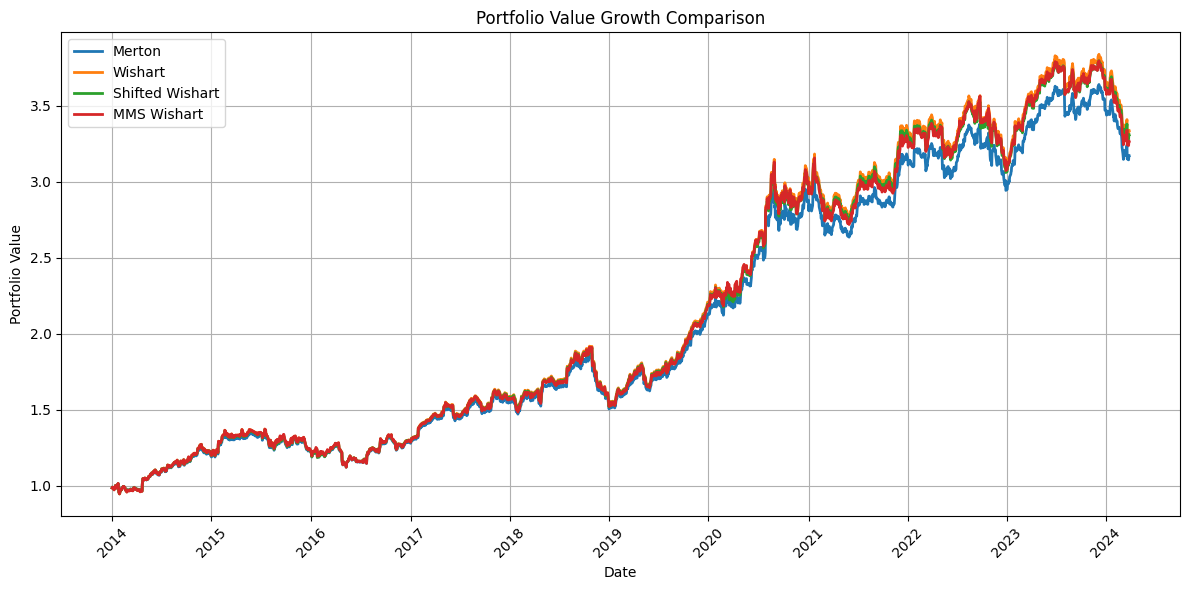

In [75]:
import matplotlib.pyplot as plt

# Ensure Date column is parsed as datetime
if not pd.api.types.is_datetime64_any_dtype(data['Date']):
    data['Date'] = pd.to_datetime(data['Date'])

plt.figure(figsize=(12, 6))
plt.plot(data['Date'], data['M_Portfolio'], label='Merton', linewidth=2)
plt.plot(data['Date'], data['W_Portfolio'], label='Wishart', linewidth=2)
plt.plot(data['Date'], data['SW_Portfolio'], label='Shifted Wishart', linewidth=2)
plt.plot(data['Date'], data['MW_Portfolio'], label='MMS Wishart', linewidth=2)
plt.xlabel('Date')
plt.ylabel('Portfolio Value')
plt.title('Portfolio Value Growth Comparison')
plt.legend()
plt.grid(True)

# Set x-axis to annual ticks only, located at years' start dates (not at integer indices)
years = data['Date'].dt.year
unique_years = sorted(years.unique())
year_locs = [data[data['Date'].dt.year == y]['Date'].iloc[0] for y in unique_years]
plt.xticks(ticks=year_locs, labels=[str(y) for y in unique_years], rotation=45)

plt.tight_layout()
plt.show()




In [76]:
import numpy as np

def sharpe_ratio(returns, risk_free):
    """
    Compute the Sharpe ratio.
    Args:
        returns (pd.Series or np.array): Return series.
        risk_free (float): Risk-free rate (per period, e.g., daily).
    Returns:
        float: Sharpe ratio.
    """
    excess = returns - risk_free
    return np.mean(excess) / np.std(excess, ddof=1)

def sortino_ratio(returns, risk_free):
    """
    Compute the Sortino ratio.
    Args:
        returns (pd.Series or np.array): Return series.
        risk_free (float): Risk-free rate (per period, e.g., daily).
    Returns:
        float: Sortino ratio.
    """
    excess = returns - risk_free
    downside = excess[excess < 0]
    downside_std = np.std(downside, ddof=1)
    # Avoid division by zero
    if downside_std == 0:
        return np.nan
    return np.mean(excess) / downside_std

# Extract returns (drop NaN for accurate statistics)
m_ret = data['M_return'].dropna()*252
w_ret = data['W_return'].dropna()*252
sw_ret = data['SW_return'].dropna()*252
mw_ret = data['MW_return'].dropna()*252

# Risk-free rate (per period): assuming r is defined elsewhere as a constant
# If r is annualized and returns are daily, convert r: r = annual_r / 252
# Else if r is already in daily units, leave as is.

# Use benchmark index returns for Sharpe/Sortino of benchmark as well:
if 'A1_returns' in data.columns:
    bench_returns = data['A1_returns'].dropna() * 252
else:
    # Fallback: compute returns from A1 price series
    bench_returns = data['A1'].pct_change().dropna() * 252

results = {}

# Calculate Sharpe and Sortino ratios
for name, ret in [('Merton', m_ret), 
                  ('Wishart', w_ret), 
                  ('Shifted Wishart', sw_ret), 
                  ('MMS Wishart', mw_ret),
                  ('Benchmark', bench_returns)]:
    sr = sharpe_ratio(ret, r)
    sor = sortino_ratio(ret, r)
    results[name] = (sr, sor)

# Print nicely
print("Sharpe and Sortino Ratios (risk-free rate: r = {:.6f}):".format(r))
print("{:<18}  {:>12}  {:>12}".format("Strategy", "Sharpe", "Sortino"))
print("-"*44)
for name, (sr, sor) in results.items():
    print("{:<18}  {:>12.4f}  {:>12.4f}".format(name, sr, sor))



Sharpe and Sortino Ratios (risk-free rate: r = 0.040000):
Strategy                  Sharpe       Sortino
--------------------------------------------
Merton                    0.0423        0.0593
Wishart                   0.0428        0.0599
Shifted Wishart           0.0428        0.0599
MMS Wishart               0.0419        0.0588
Benchmark                 0.0234        0.0279


In [77]:
# Compute maximum drawdown for each portfolio and the A1 benchmark

def max_drawdown(series):
    """
    Calculate the maximum drawdown for a time series (e.g., portfolio value).
    """
    cumulative_max = series.cummax()
    drawdown = (series - cumulative_max) / cumulative_max
    return drawdown.min()

# Define which columns to check
portfolio_columns = [
    ('Merton', 'M_Portfolio'),
    ('Wishart', 'W_Portfolio'),
    ('Shifted Wishart', 'SW_Portfolio'),
    ('MMS Wishart', 'MW_Portfolio')
]
# Add benchmark (A1)
portfolio_columns.append(('Benchmark (A1)', 'A1'))

# Compute and print results
print("\nMaximum Drawdown (as percentage declines from peak):")
print("{:<18}  {:>20}".format("Strategy", "Max Drawdown (%)"))
print("-"*40)
for label, col in portfolio_columns:
    if col in data.columns:
        vals = data[col].dropna()
        if not vals.empty:
            mdd = max_drawdown(vals) * 100  # convert to percent
            print("{:<18}  {:>20.2f}".format(label, mdd))
        else:
            print("{:<18}  {:>20}".format(label, "n/a"))
    else:
        print("{:<18}  {:>20}".format(label, "n/a"))



Maximum Drawdown (as percentage declines from peak):
Strategy                Max Drawdown (%)
----------------------------------------
Merton                            -19.31
Wishart                           -20.58
Shifted Wishart                   -20.36
MMS Wishart                       -20.36
Benchmark (A1)                    -33.92


In [78]:
data

,Date,A1,A2,A1_returns,A2_returns,A1_vol,A2_vol,Regime_A1_vol,Regime_vol_ret,is_last_in_data,...,MW_P1,MW_P2,M_return,W_return,SW_return,MW_return,M_Portfolio,W_Portfolio,SW_Portfolio,MW_Portfolio
0,2014-01-02,1831.979980,17.296656,NaN,NaN,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,-0.013566,-0.014286,-0.014089,-0.014533,0.986434,0.985714,0.985911,0.985467
1,2014-01-03,1831.369995,16.916723,-0.000333,-0.022210,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,0.004920,0.005065,0.004983,0.005309,0.991288,0.990707,0.990824,0.990699
2,2014-01-06,1826.770020,17.008970,-0.002515,0.005438,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670046,-0.007653,-0.007834,-0.007693,-0.008319,0.983702,0.982945,0.983202,0.982457
3,2014-01-07,1837.880005,16.887327,0.006063,-0.007177,NaN,NaN,NaN,NaN,False,...,-0.603317,0.670045,0.004211,0.004405,0.004344,0.004506,0.987844,0.987275,0.987473,0.986884
4,2014-01-08,1837.489990,16.994274,-0.000212,0.006313,NaN,NaN,NaN,NaN,False,...,-0.603318,0.670045,-0.008084,-0.008498,-0.008378,-0.008674,0.979859,0.978885,0.979200,0.978325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2024-03-21,5241.529785,171.369995,0.003231,-0.041716,0.006013,0.015002,0.0,NaN,False,...,-0.629707,0.645908,0.004225,0.004287,0.004223,0.004461,3.161934,3.326287,3.298598,3.256167
2496,2024-03-22,5234.180176,172.279999,-0.001403,0.005296,0.006043,0.015049,0.0,NaN,False,...,-0.629796,0.646002,-0.003398,-0.003429,-0.003397,-0.003301,3.151190,3.314882,3.287395,3.245417
2497,2024-03-25,5218.189941,170.850006,-0.003060,-0.008335,0.006012,0.015064,0.0,NaN,False,...,-0.629888,0.646099,-0.002512,-0.002532,-0.002511,-0.002403,3.143275,3.306488,3.279141,3.237618
2498,2024-03-26,5203.580078,169.710007,-0.002804,-0.006695,0.006086,0.014857,0.0,NaN,False,...,-0.629984,0.646198,0.008586,0.008657,0.008585,0.008307,3.170265,3.335113,3.307291,3.264511
